In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Basic Perceptron Implementation

In [3]:
class Perceptron :
    """ Perceptron classifier """

    def __init__ ( self , learning_rate =0.01 , n_epochs =50 ,
        random_state = None ) :
        """
        Initialize Perceptron
        Parameters :
        learning_rate : eta-learning rate ( default 0.01)
        n_epochs : number of passes over training data ( default
        50)
        random_state : seed for random initialization ( default
        None )
        """
        self.lr = learning_rate
        self.n_epochs = n_epochs
        self.random_state = random_state
        self.weights = None
        self.bias = None
        self.errors_history = [] # Track errors per epoch
        self.weights_history = [] # Track weights evolution

    def net_input ( self , X ) :
        """ Compute linear combination """
        return np.dot (X , self.weights ) + self.bias

    def predict ( self , X ) :
        """ Predict class labels ( -1 or 1) """
        return np.where ( self.net_input ( X ) >= 0.0 , 1 , -1)

    def fit ( self , X , y , verbose = True ) :
        """
        Train the Perceptron

        Parameters :
        X : training data of shape ( n_samples , n_features )
        y : target values ( -1 or 1) of shape ( n_samples ,)

        verbose : print progress

        Returns :
        self : trained Perceptron
        """
        n_samples , n_features = X.shape

        # Set random seed for reproducibility
        if self.random_state :
            np.random.seed ( self.random_state )

        # Initialize weights and bias
        self.weights = np.zeros ( n_features )
        self.bias = 0
        self.errors_history = []
        self.weights_history = [ self.weights.copy () ]

        for epoch in range ( self.n_epochs ) :
            errors = 0

            for xi , target in zip (X , y ) :
            # Compute prediction
                prediction = self.predict ( xi.reshape (1 , -1) ) [0]

                # Update if prediction is wrong
                if prediction != target :
                    update = self.lr * target
                    self.weights += update * xi
                    self.bias += update
                    errors += 1

                self.errors_history.append ( errors )
                self.weights_history.append ( self.weights.copy () )

            if verbose and ( epoch + 1) % 10 == 0:
                print (f" Epoch { epoch +1}/{ self.n_epochs } , Errors :    { errors } " )

            # Early stopping if no errors
            if errors == 0:
                if verbose :
                    print (f" Converged at epoch { epoch + 1} " )
                break

        return self

    def score ( self , X , y ) :
        """ Compute accuracy score """
        predictions = self.predict ( X )
        return np.mean ( predictions == y )

In [4]:
# Test on simple data
X , y = make_classification (
n_samples =200 , n_features =2 , n_redundant =0 ,
n_clusters_per_class =1 , class_sep =1.5 , random_state =42
)
y = np.where ( y == 0 , -1 , 1) # Convert to -1/1

# Train-test split
X_train , X_test , y_train , y_test = train_test_split (X , y ,
test_size =0.2 , random_state =42)

# Standardize ( important for Perceptron )
scaler = StandardScaler ()
X_train_scaled = scaler.fit_transform ( X_train )
X_test_scaled = scaler.transform ( X_test )

# Train Perceptron
perceptron = Perceptron ( learning_rate =0.1 , n_epochs =50 ,
random_state =42)
perceptron.fit ( X_train_scaled , y_train )

# Evaluate
train_acc = perceptron.score ( X_train_scaled , y_train )
test_acc = perceptron.score ( X_test_scaled , y_test )

print (f" \nTraining accuracy : { train_acc :.2%} " )
print (f" Test accuracy : { test_acc :.2%} " )
print (f" Final weights : { perceptron.weights } " )
print (f" Final bias : { perceptron.bias :.4f} " )

 Epoch 10/50 , Errors :    16 
 Epoch 20/50 , Errors :    16 
 Epoch 30/50 , Errors :    16 
 Epoch 40/50 , Errors :    18 
 Epoch 50/50 , Errors :    14 
 
Training accuracy : 90.62% 
 Test accuracy : 85.00% 
 Final weights : [ 0.39927481 -0.13498262] 
 Final bias : 0.1000 


# Learning Logic Gates with Perceptron

In [5]:
# Data for logic gates ( in -1/1 format )
X_logic = np.array ([[0 ,0] , [0 ,1] , [1 ,0] , [1 ,1]])

# Truth tables in -1/1 format ( -1 for 0 , 1 for 1)
y_and = np.array ([ -1 , -1 , -1 , 1]) # AND : only (1 ,1) is positive
y_or = np.array ([ -1 , 1 , 1 , 1]) # OR : only (0 ,0) is negative
y_nand = np.array ([1 , 1 , 1 , -1]) # NAND : only (1 ,1) is negative
y_nor = np.array ([1 , -1 , -1 , -1]) # NOR : only (0 ,0) is positive
y_xor = np.array ([ -1 , 1 , 1 , -1]) # XOR : impossible with single neuron

def train_and_evaluate_perceptron (X , y , gate_name , learning_rate=0.1 , epochs =20) :
    """ Train Perceptron on logic gate and evaluate """
    print (f" \n {'='*50} " )
    print (f" Training Perceptron on { gate_name } gate " )
    print ('=' *50)

    perceptron = Perceptron ( learning_rate = learning_rate , n_epochs= epochs , random_state =42)
    perceptron.fit (X , y , verbose = False )

    predictions = perceptron.predict ( X )

    print (f" Weights : { perceptron.weights } " )
    print (f" Bias : { perceptron.bias :.4f} " )
    print ( " \nTruth Table : " )
    print ( " A B | Target | Prediction | Status " )
    print ( "----+--------+------------+-------" )
    for i , (x , target , pred ) in enumerate ( zip (X , y , predictions ) ):
        status = " OK " if target == pred else " FAIL "
        target_val = 1 if target == 1 else 0
        pred_val = 1 if pred == 1 else 0
        print (f" { int ( x [0]) } { int ( x [1]) } | { target_val } | { pred_val } | { status } " )

    accuracy = np.mean ( predictions == y )
    print (f" \nAccuracy : { accuracy :.2%} " )
    print (f" Epochs to converge : { len ( perceptron.errors_history ) } "
    )

    # Plot error evolution
    plt.figure ( figsize =(10 , 4) )
    plt.subplot (1 , 2 , 1)
    plt.plot ( perceptron.errors_history , marker ='o', linestyle ='-', linewidth =2)
    plt.xlabel ('Epoch')
    plt.ylabel ('Number of errors')
    plt.title (f'{ gate_name } Gate-Error Evolution')
    plt.grid ( True , alpha =0.3)
    plt.ylim ( -0.5 , 4.5)

    # Plot weight evolution
    plt.subplot (1 , 2 , 2)
    weights_history = np.array ( perceptron.weights_history )
    plt.plot ( weights_history [: , 0] , label ='Weight 1', linewidth
    =2)
    plt.plot ( weights_history [: , 1] , label ='Weight 2', linewidth
    =2)
    plt.xlabel ('Update step')
    plt.ylabel ('Weight value')
    plt.title (f'{ gate_name } Gate-Weight Evolution')
    plt.legend ()
    plt.grid ( True , alpha =0.3)
    plt.tight_layout ()
    plt.show ()

    return perceptron


 
 Training Perceptron on  AND  gate 
 Weights : [0.2 0.1] 
 Bias : -0.2000 
 
Truth Table : 
 A B | Target | Prediction | Status 
----+--------+------------+-------
 0 0 | 0 | 0 |  OK  
 0 1 | 0 | 0 |  OK  
 1 0 | 0 | 0 |  OK  
 1 1 | 1 | 1 |  OK  
 
Accuracy : 100.00% 
 Epochs to converge : 16 


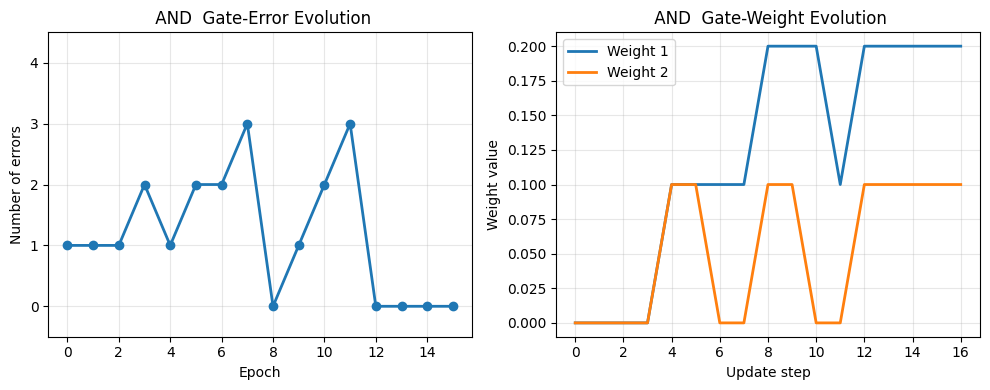

 
 Training Perceptron on  OR  gate 
 Weights : [0.1 0.1] 
 Bias : -0.1000 
 
Truth Table : 
 A B | Target | Prediction | Status 
----+--------+------------+-------
 0 0 | 0 | 0 |  OK  
 0 1 | 1 | 1 |  OK  
 1 0 | 1 | 1 |  OK  
 1 1 | 1 | 1 |  OK  
 
Accuracy : 100.00% 
 Epochs to converge : 16 


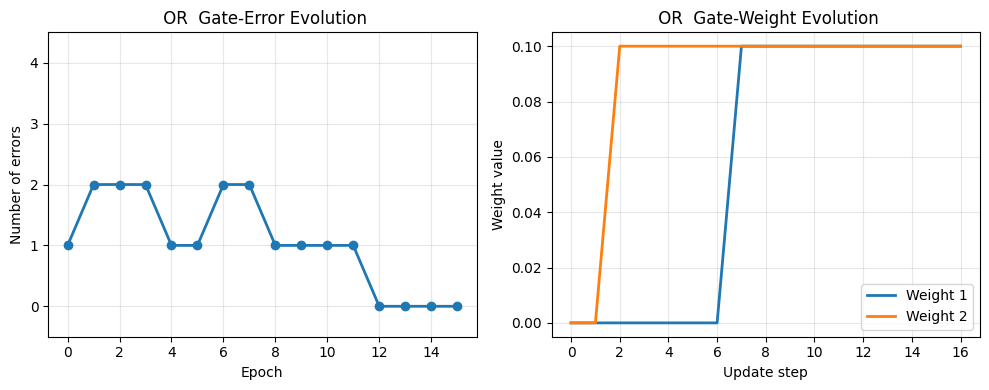

 
 Training Perceptron on  NAND  gate 
 Weights : [-0.2 -0.1] 
 Bias : 0.2000 
 
Truth Table : 
 A B | Target | Prediction | Status 
----+--------+------------+-------
 0 0 | 1 | 1 |  OK  
 0 1 | 1 | 1 |  OK  
 1 0 | 1 | 1 |  OK  
 1 1 | 0 | 0 |  OK  
 
Accuracy : 100.00% 
 Epochs to converge : 24 


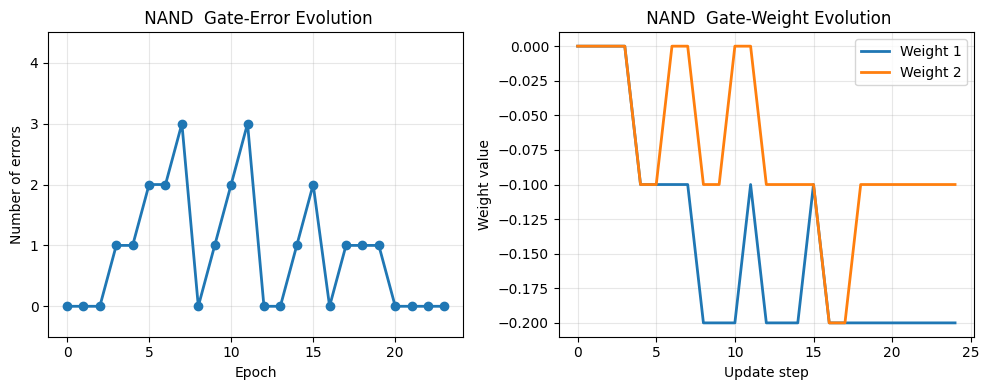

 
 Training Perceptron on  NOR  gate 
 Weights : [-0.1 -0.1] 
 Bias : 0.0000 
 
Truth Table : 
 A B | Target | Prediction | Status 
----+--------+------------+-------
 0 0 | 1 | 1 |  OK  
 0 1 | 0 | 0 |  OK  
 1 0 | 0 | 0 |  OK  
 1 1 | 0 | 0 |  OK  
 
Accuracy : 100.00% 
 Epochs to converge : 16 


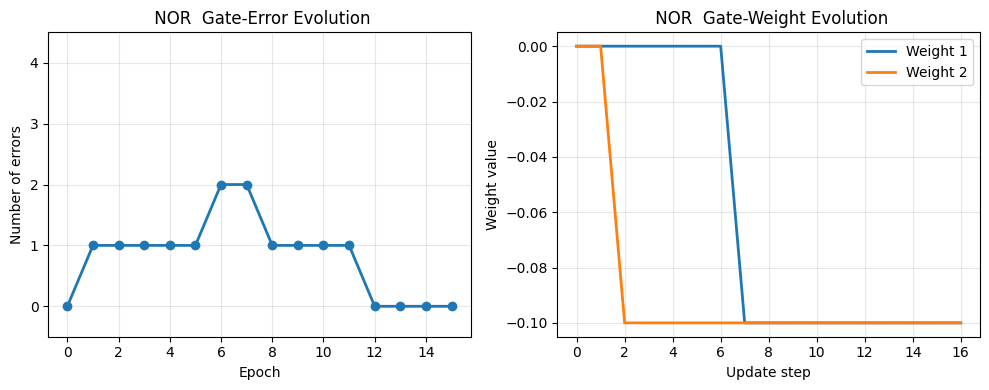

 
 Training Perceptron on  XOR  gate 
 Weights : [-0.1  0. ] 
 Bias : 0.0000 
 
Truth Table : 
 A B | Target | Prediction | Status 
----+--------+------------+-------
 0 0 | 0 | 1 |  FAIL  
 0 1 | 1 | 1 |  OK  
 1 0 | 1 | 0 |  FAIL  
 1 1 | 0 | 0 |  OK  
 
Accuracy : 50.00% 
 Epochs to converge : 80 


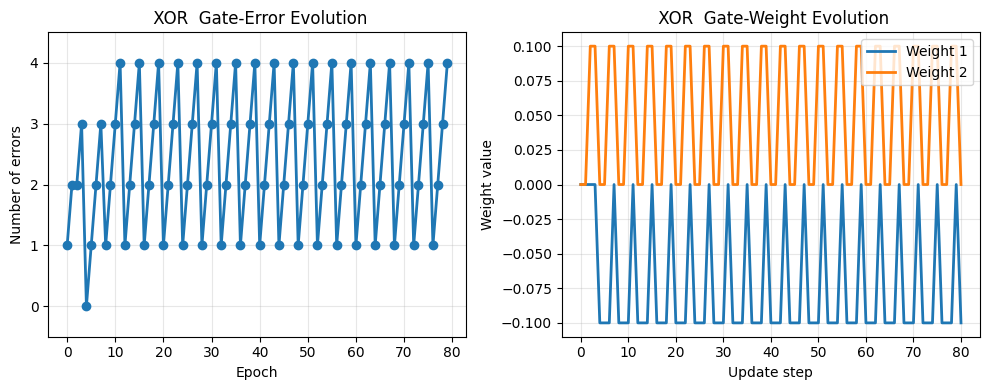

In [6]:
# Train on different gates
p_and  = train_and_evaluate_perceptron ( X_logic , y_and , " AND " )
p_or   = train_and_evaluate_perceptron ( X_logic , y_or , " OR " )
p_nand = train_and_evaluate_perceptron ( X_logic , y_nand , " NAND " )
p_nor  = train_and_evaluate_perceptron ( X_logic , y_nor , " NOR " )
p_xor  = train_and_evaluate_perceptron ( X_logic , y_xor , " XOR " )

# Observations on XOR

 
  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  = 
 ANALYSIS OF XOR FAILURE 
 =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  = 
 Final weights after 100 epochs : [-0.1  0. ] 
 Final bias : 0.0000 
 Final errors : 4/4 


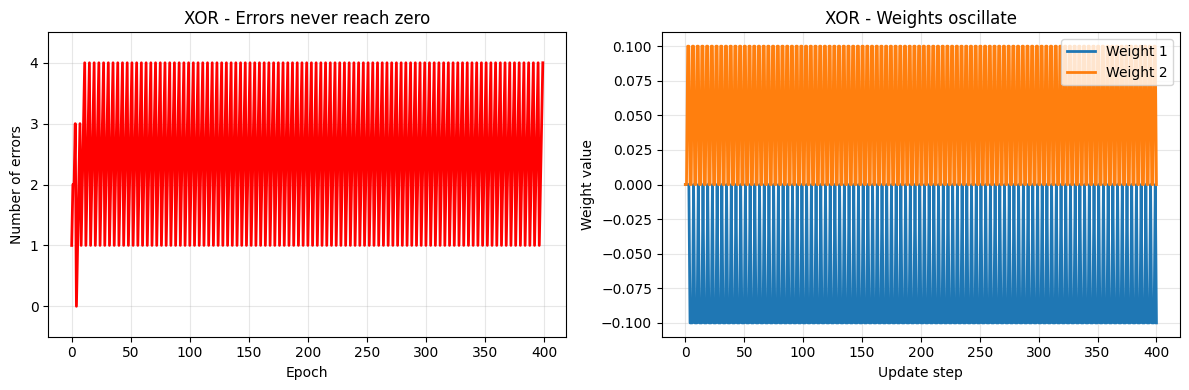

/tmp/ipykernel_35093/1415520096.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend ()


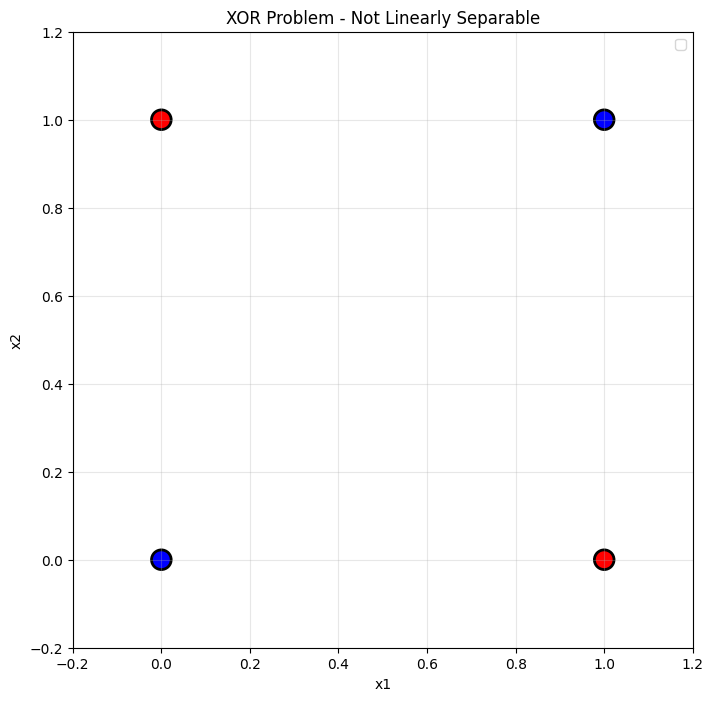

 
  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  = 
 CONCLUSION : XOR is not linearly separable 
 =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  = 
 No single straight line can separate the red and blue points.
 This is why the Perceptron cannot learn XOR.
 A multi - layer network is needed for such problems.


In [7]:
# Detailed analysis of XOR failure
print ( " \n " + " = " *60)
print ( " ANALYSIS OF XOR FAILURE " )
print ( " = " *60)

X_xor = np.array ([[0 ,0] , [0 ,1] , [1 ,0] , [1 ,1]])
y_xor = np.array ([ -1 , 1 , 1 , -1])

# Try with many epochs
p_xor_detailed = Perceptron ( learning_rate =0.1 , n_epochs =100 ,
random_state =42)
p_xor_detailed.fit ( X_xor , y_xor , verbose = False )

print (f" Final weights after 100 epochs : { p_xor_detailed.weights } ")
print (f" Final bias : { p_xor_detailed.bias :.4f} " )
print (f" Final errors : { p_xor_detailed.errors_history [ -1]}/4 " )

 # Show that weights oscillate
plt.figure ( figsize =(12 , 4) )

plt.subplot (1 , 2 , 1)
plt.plot ( p_xor_detailed.errors_history , linewidth =2 , color ='red')
plt.xlabel ('Epoch')
plt.ylabel ('Number of errors')
plt.title ('XOR - Errors never reach zero')
plt.grid ( True , alpha =0.3)
plt.ylim ( -0.5 , 4.5)

plt.subplot (1 , 2 , 2)
weights_history = np.array ( p_xor_detailed.weights_history )
plt.plot ( weights_history [: , 0] , label ='Weight 1', linewidth =2)
plt.plot ( weights_history [: , 1] , label ='Weight 2', linewidth =2)
plt.xlabel ('Update step')
plt.ylabel ('Weight value')
plt.title ('XOR - Weights oscillate')
plt.legend ()
plt.grid ( True , alpha =0.3)

plt.tight_layout ()
plt.show ()

# Geometric explanation
plt.figure ( figsize =(8 , 8) )
colors = ['blue'if y == -1 else'red'for y in y_xor ]
plt.scatter ( X_xor [: , 0] , X_xor [: , 1] , c = colors , s =200 , edgecolors
='black', linewidth =2)

# Try to plot decision boundary from final weights
x_line = np.linspace ( -0.5 , 1.5 , 100)
if p_xor_detailed.weights [1] != 0:
    y_line = -( p_xor_detailed.weights [0] * x_line + xor_detailed.bias ) / p_xor_detailed.weights[1]
    plt.plot ( x_line , y_line ,'g--', linewidth =2 , label ='Attempted boundary')

plt.xlabel ('x1')
plt.ylabel ('x2')
plt.title ('XOR Problem - Not Linearly Separable')
plt.grid ( True , alpha =0.3)
plt.xlim ( -0.2 , 1.2)
plt.ylim ( -0.2 , 1.2)
plt.legend ()
plt.show ()

print ( " \n " + " = " *60)
print ( " CONCLUSION : XOR is not linearly separable " )
print ( " = " *60)
print ( " No single straight line can separate the red and blue points." )
print ( " This is why the Perceptron cannot learn XOR." )
print ( " A multi - layer network is needed for such problems." )

# Eﬀect of Learning Rate


TESTING DIFFERENT LEARNING RATES ON AND GATE


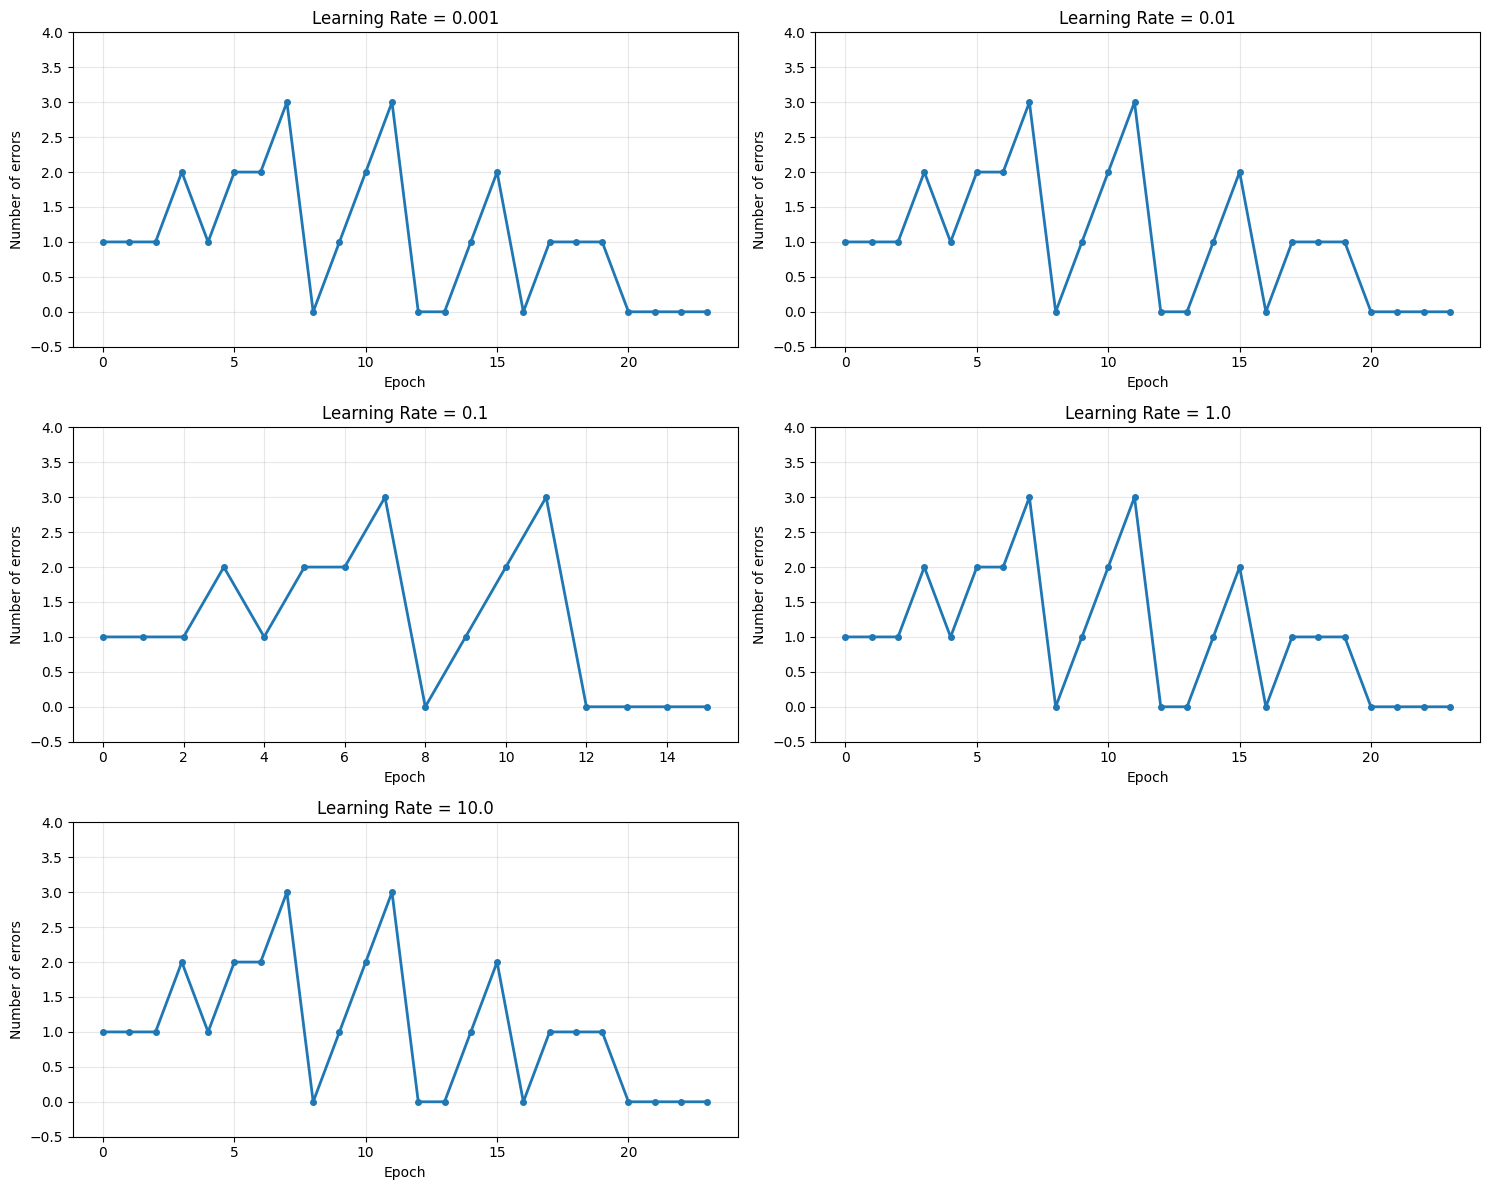


LEARNING RATE COMPARISON
LR         Final Weights             Bias       Epochs     Final Errors
----------------------------------------------------------------------
0.0010     [0.002, 0.001]            -0.003     24         0           
0.0100     [0.020, 0.010]            -0.030     24         0           
0.1000     [0.200, 0.100]            -0.200     16         0           
1.0000     [2.000, 1.000]            -3.000     24         0           
10.0000    [20.000, 10.000]          -30.000    24         0           

TESTING DIFFERENT LEARNING RATES ON COMPLEX DATA


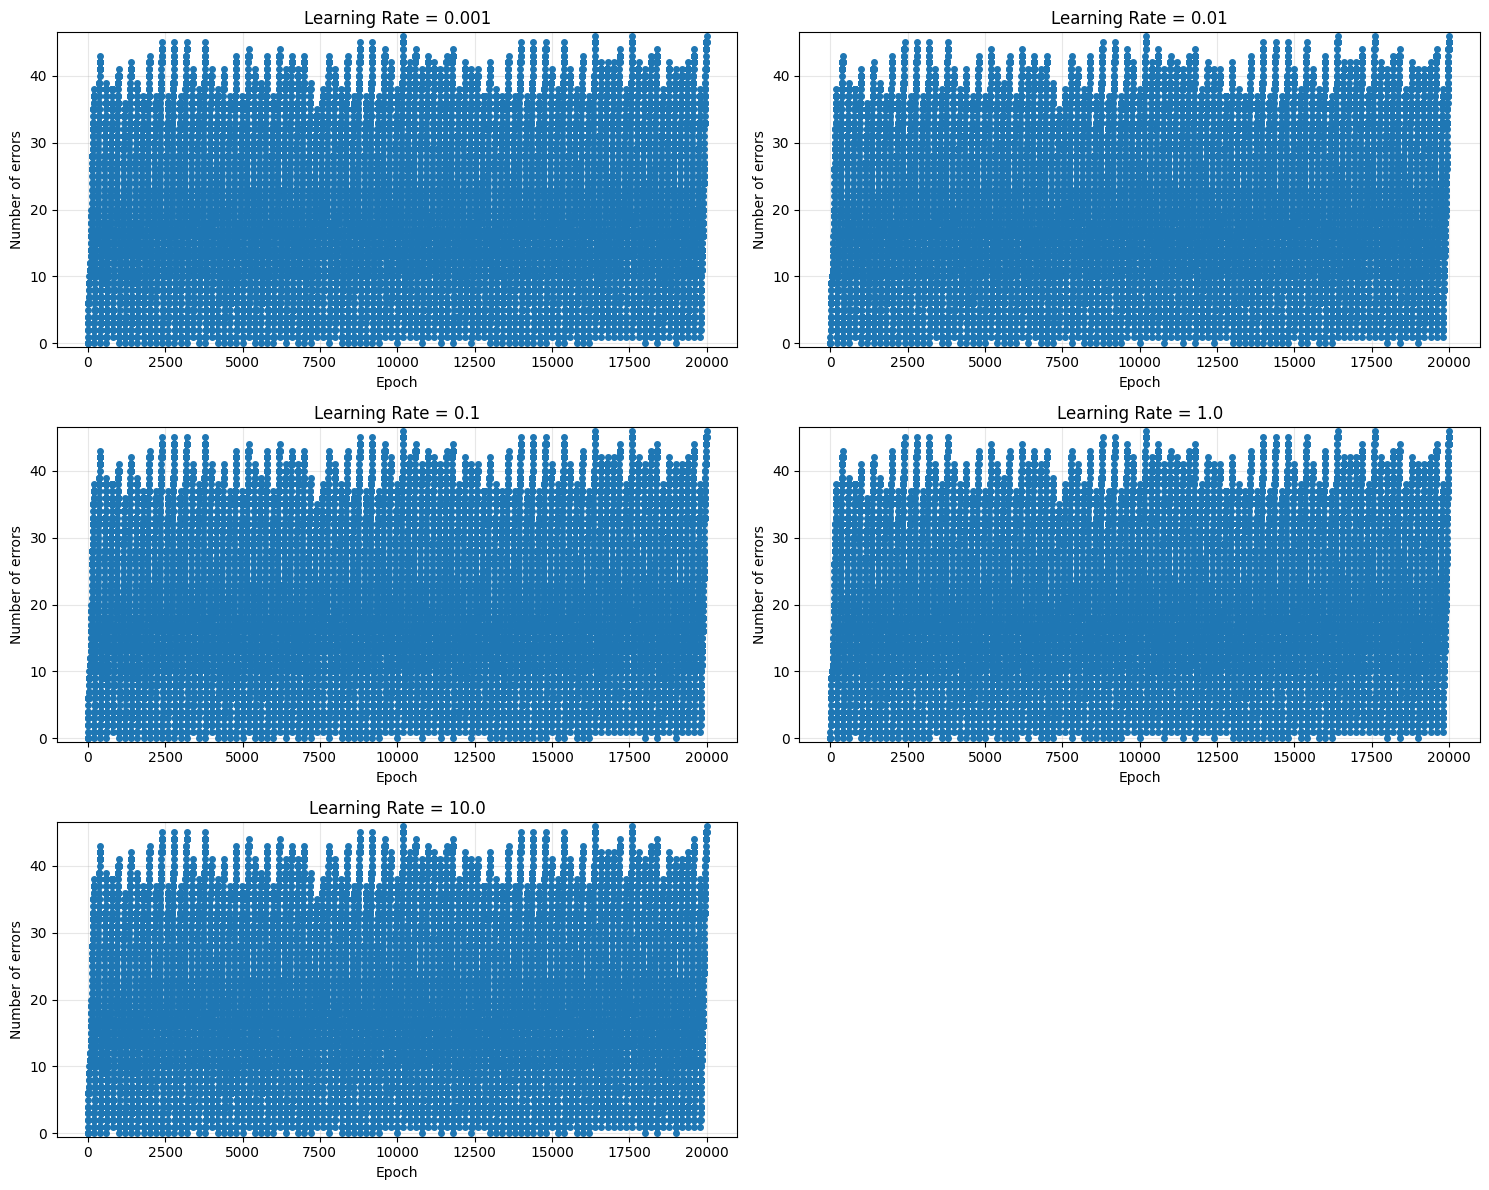


LEARNING RATE COMPARISON
LR         Final Weights             Bias       Epochs     Final Errors
----------------------------------------------------------------------
0.0010     [0.003, -0.003]           -0.001     100        46          
0.0100     [0.027, -0.025]           -0.010     100        46          
0.1000     [0.265, -0.255]           -0.100     100        46          
1.0000     [2.653, -2.547]           -1.000     100        46          
10.0000    [26.532, -25.473]         -10.000    100        46          


In [8]:
def compare_perceptron_learning_rates(X, y, learning_rates=[0.001, 0.01, 0.1, 1.0, 10.0], epochs=50):
    """
    Compare Perceptron performance with different learning rates
    """
    plt.figure(figsize=(15, 12))
    results = {}

    for i, lr in enumerate(learning_rates):
        # Train Perceptron
        p = Perceptron(learning_rate=lr, n_epochs=epochs, random_state=42)
        p.fit(X, y, verbose=False)

        # Plot error evolution
        plt.subplot(3, 2, i+1)
        plt.plot(p.errors_history, linewidth=2, marker='o', markersize=4)
        plt.xlabel('Epoch')
        plt.ylabel('Number of errors')
        plt.title(f'Learning Rate = {lr}')
        plt.grid(True, alpha=0.3)
        plt.ylim(-0.5, max(4, max(p.errors_history)+0.5))

        # Store results
        final_errors = p.errors_history[-1] if p.errors_history else 0
        epochs_to_converge = len(p.errors_history) if final_errors == 0 else epochs

        results[lr] = {
'final_weights': p.weights.copy(),
'bias': p.bias,
'final_errors': final_errors,
'epochs_to_converge': epochs_to_converge,
           'weights_history': np.array(p.weights_history)
        }

    plt.tight_layout()
    plt.show()

    # Print comparison
    print("\n" + "="*70)
    print("LEARNING RATE COMPARISON")
    print("="*70)
    print(f"{'LR':<10} {'Final Weights':<25} {'Bias':<10} {'Epochs':<10} {'Final Errors':<12}")
    print("-"*70)

    for lr, res in results.items():
        weights_str = f"[{res['final_weights'][0]:.3f}, {res['final_weights'][1]:.3f}]"
        print(f"{lr:<10.4f} {weights_str:<25} {res['bias']:<10.3f} "
              f"{res['epochs_to_converge']:<10} {res['final_errors']:<12}")

    return results

# Test on AND gate
print("\n" + "="*70)
print("TESTING DIFFERENT LEARNING RATES ON AND GATE")
print("="*70)
results_and = compare_perceptron_learning_rates(X_logic, y_and)

# Test on a more complex dataset
X_comp, y_comp = make_classification(
    n_samples=200, n_features=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.0, random_state=42
)
y_comp = np.where(y_comp == 0, -1, 1)

scaler = StandardScaler()
X_comp_scaled = scaler.fit_transform(X_comp)

print("\n" + "="*70)
print("TESTING DIFFERENT LEARNING RATES ON COMPLEX DATA")
print("="*70)
results_comp = compare_perceptron_learning_rates(X_comp_scaled, y_comp, epochs=100)

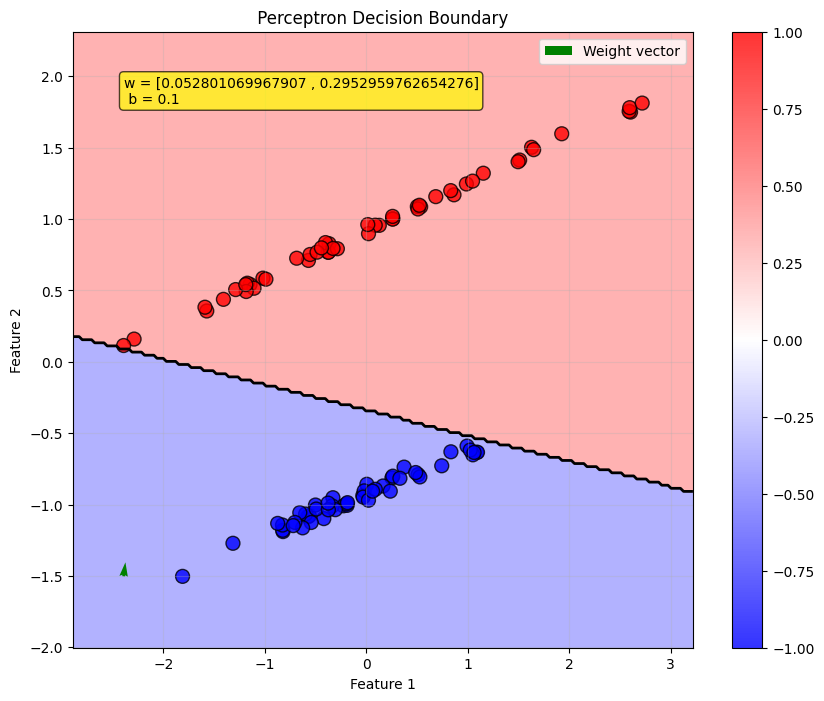

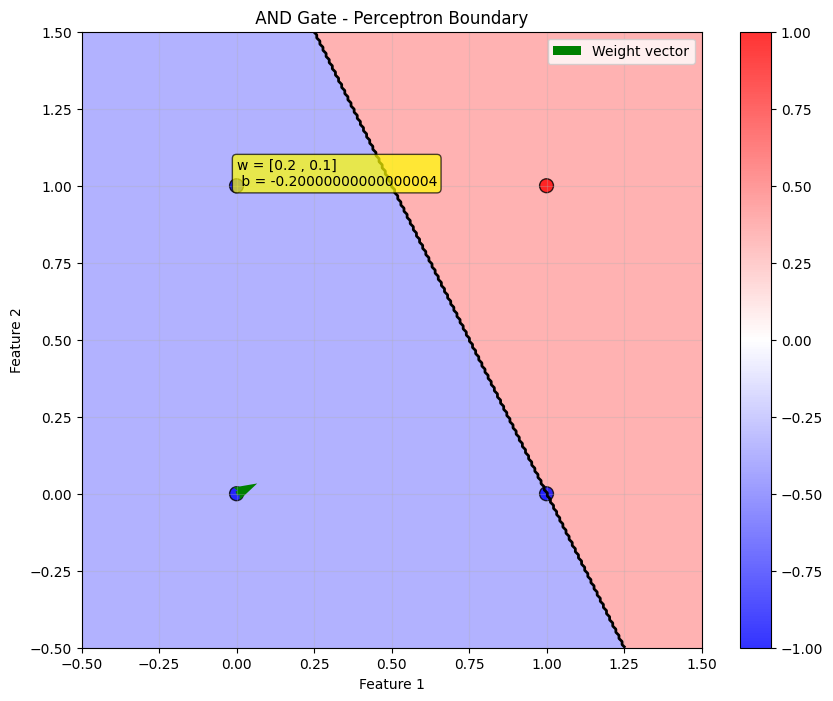

In [9]:
def plot_perceptron_decision_boundary ( perceptron , X , y , title = "Perceptron Decision Boundary " ) :
    """
    Plot the decision boundary of a trained Perceptron
    """
    # Create mesh grid
    x_min , x_max = X [: , 0]. min () - 0.5 , X [: , 0]. max () + 0.5
    y_min , y_max = X [: , 1]. min () - 0.5 , X [: , 1]. max () + 0.5
    xx , yy = np . meshgrid (
    np . linspace ( x_min , x_max , 200) ,
    np . linspace ( y_min , y_max , 200) )

    # Predict on grid
    Z = perceptron . predict ( np . c_ [ xx . ravel () , yy . ravel () ])
    Z = Z . reshape ( xx . shape )

    # Plot
    plt . figure ( figsize =(10 , 8) )
    plt . contourf ( xx , yy , Z , alpha =0.3 , levels =[ -1 , 0 , 1] , colors=['blue','red'])
    plt . contour ( xx , yy , Z , levels =[0] , colors ='black', linewidths=2)
    # Plot data points
    scatter = plt . scatter ( X [: , 0] , X [: , 1] , c =y ,
    cmap ='bwr', edgecolors ='black', s =100 ,
    alpha =0.8)

    # Plot weight vector ( direction of decision boundary )
    if perceptron . weights is not None :
        # The decision boundary is perpendicular to the weight    vector
        w = perceptron . weights
        b = perceptron . bias

        # Plot weight vector
        origin = np . array ([ x_min + 0.5 , y_min + 0.5])
        plt . quiver ( origin [0] , origin [1] , w [0] , w [1] ,    angles ='xy', scale_units ='xy', scale =3 , color ='green', label ='Weight vector', width=0.02)

        # Add text for weights and bias
        plt.text( x_min + 0.5 , y_max - 0.5 ,f'w = [{ w[0] } , { w[1] }]\n b = { b }',bbox = dict ( boxstyle = "round,pad =0.3" , facecolor = "yellow" , alpha =0.7) )

    plt . xlabel ('Feature 1')
    plt . ylabel ('Feature 2')
    plt . title ( title )
    plt . colorbar ( scatter )
    plt . grid ( True , alpha =0.3)
    plt . legend ()
    plt . show ()

# Generate and plot for a simple dataset
X_viz , y_viz = make_classification (
n_samples =100 , n_features =2 , n_redundant =0 ,
n_clusters_per_class =1 , class_sep =2.0 , random_state =42
)
y_viz = np . where ( y_viz == 0 , -1 , 1)

scaler = StandardScaler ()
X_viz_scaled = scaler . fit_transform ( X_viz )

p_viz = Perceptron ( learning_rate =0.1 , n_epochs =50 , random_state
=42)
p_viz . fit ( X_viz_scaled , y_viz , verbose = False )

plot_perceptron_decision_boundary ( p_viz , X_viz_scaled , y_viz ," Perceptron Decision Boundary " )
# Plot for AND gate
p_and_viz = Perceptron ( learning_rate =0.1 , n_epochs =20 ,random_state =42)
p_and_viz . fit ( X_logic , y_and , verbose = False )
plot_perceptron_decision_boundary ( p_and_viz , X_logic , y_and ," AND Gate - Perceptron Boundary ")

# Eﬀect of Data Ordering


AND Gate - Different initial orders:

EFFECT OF DATA ORDERING ON PERCEPTRON
Experiment 1: Converged in 20 epochs, Weights = [0.100, 0.200]
Experiment 2: Converged in 20 epochs, Weights = [0.100, 0.200]
Experiment 3: Converged in 20 epochs, Weights = [0.200, 0.100]


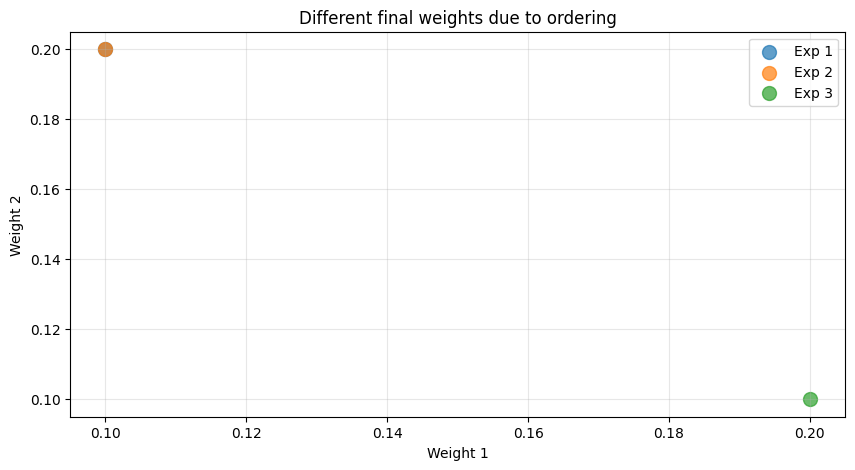

In [10]:
def demonstrate_order_sensitivity(X, y, n_experiments=5):
    """
    Demonstrate that Perceptron convergence depends on example
    order
    """
    print("\n" + "="*60)
    print("EFFECT OF DATA ORDERING ON PERCEPTRON")
    print("="*60)

    results = []

    for exp in range(n_experiments):
        # Shuffle data differently each time
        indices = np.random.permutation(len(X))
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Train Perceptron
        p = Perceptron(learning_rate=0.1, n_epochs=50,
                       random_state=None)
        p.fit(X_shuffled, y_shuffled, verbose=False)

        epochs = len(p.errors_history)
        final_weights = p.weights.copy()

        results.append({
            'experiment': exp + 1,
            'epochs': epochs,
            'weights': final_weights
        })

        print(f"Experiment {exp+1}: Converged in {epochs} epochs, "
              f"Weights = [{final_weights[0]:.3f}, {final_weights[1]:.3f}]")

    # Plot differences
    plt.figure(figsize=(10, 5))

    for i, res in enumerate(results):
        plt.scatter(res['weights'][0], res['weights'][1],
                    s=100, label=f'Exp {i+1}', alpha=0.7)

    plt.xlabel('Weight 1')
    plt.ylabel('Weight 2')
    plt.title('Different final weights due to ordering')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    return results

# Test on AND gate
print("\nAND Gate - Different initial orders:")
order_results = demonstrate_order_sensitivity(X_logic, y_and,
                                               n_experiments=3)

# Voting Perceptron

In [11]:
class VotingPerceptron:
    """
    Voting Perceptron - keeps track of all weight vectors
    and votes based on their survival time
    """

    def __init__(self, learning_rate=0.01, n_epochs=50):
        self.lr = learning_rate
        self.n_epochs = n_epochs
        self.weight_vectors = []  # List of (weights, bias, count)
        self.current_weights = None
        self.current_bias = None
        self.current_count = 0

    def predict(self, X):
        """Predict using voting"""
        if not self.weight_vectors:
            return np.zeros(len(X))

        predictions = np.zeros(len(X))

        for weights, bias, count in self.weight_vectors:
            pred = np.where(np.dot(X, weights) + bias >= 0, 1, -1)
            predictions += count * pred

        return np.where(predictions >= 0, 1, -1)

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.current_weights = np.zeros(n_features)
        self.current_bias = 0
        self.current_count = 1
        self.weight_vectors = []

        for epoch in range(self.n_epochs):
            for xi, target in zip(X, y):
                prediction = np.where(np.dot(xi, self.
                                             current_weights) + self.current_bias >= 0, 1,
                                      -1)

                if prediction != target:
                    # Save current vector with its count
                    self.weight_vectors.append(
                        (self.current_weights.copy(), self.
                         current_bias, self.current_count)
                    )

                    # Update
                    update = self.lr * target
                    self.current_weights += update * xi
                    self.current_bias += update
                    self.current_count = 1
                else:
                    self.current_count += 1

        # Add final vector
        self.weight_vectors.append(
            (self.current_weights.copy(), self.current_bias, self
             .current_count)
        )

        return self

    def score(self, X, y):
        predictions = self.predict(X)
        return np.mean(predictions == y)

# Compare standard vs voting Perceptron
X_comp, y_comp = make_classification(
    n_samples=200, n_features=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.2, random_state=42
)
y_comp = np.where(y_comp == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X_comp,
    y_comp, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Standard Perceptron
std_p = Perceptron(learning_rate=0.1, n_epochs=50, random_state
                   =42)
std_p.fit(X_train_scaled, y_train, verbose=False)
std_test_acc = std_p.score(X_test_scaled, y_test)

# Voting Perceptron
voting_p = VotingPerceptron(learning_rate=0.1, n_epochs=50)
voting_p.fit(X_train_scaled, y_train)
voting_test_acc = voting_p.score(X_test_scaled, y_test)

print("\n" + "="*60)
print("STANDARD VS VOTING PERCEPTRON")
print("="*60)
print(f"Standard Perceptron - Test accuracy: {std_test_acc:.2%}")
print(f"Voting Perceptron - Test accuracy: {voting_test_acc:.2%}"
)
print(f"Number of weight vectors saved: {len(voting_p.
      weight_vectors)}")


STANDARD VS VOTING PERCEPTRON
Standard Perceptron - Test accuracy: 78.33%
Voting Perceptron - Test accuracy: 90.00%
Number of weight vectors saved: 1024


# Perceptron on Real Dataset: Iris

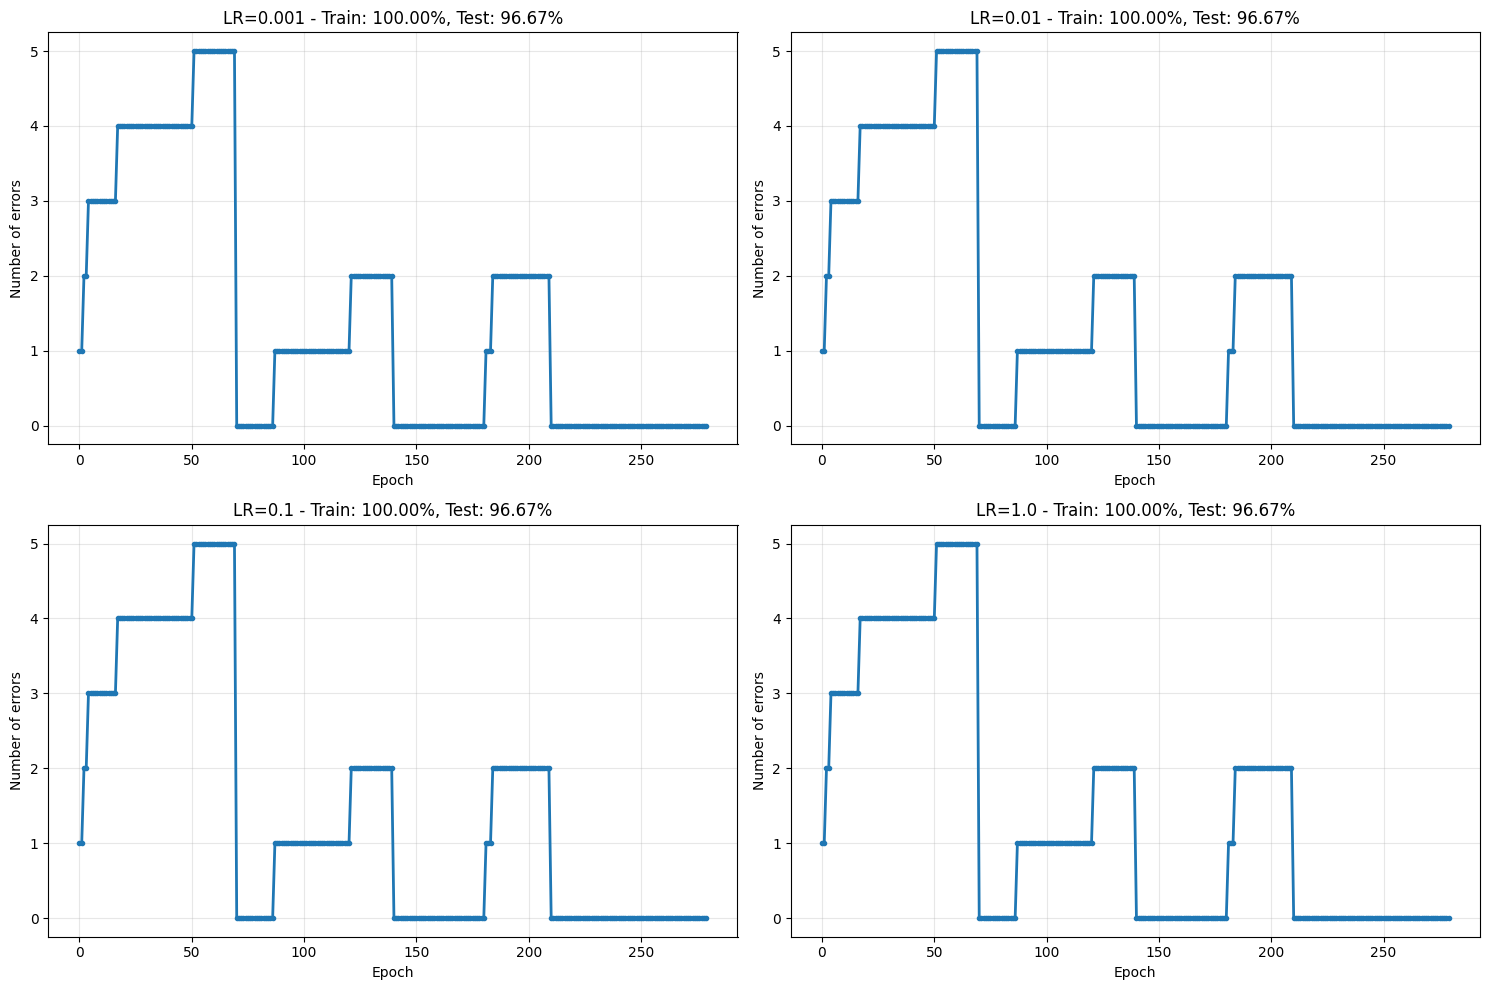


PERCEPTRON ON IRIS DATASET
Best learning rate: 0.001
Best test accuracy: 96.67%
Final weights: [ 0.0031786  -0.00123953]
Final bias: 0.0010


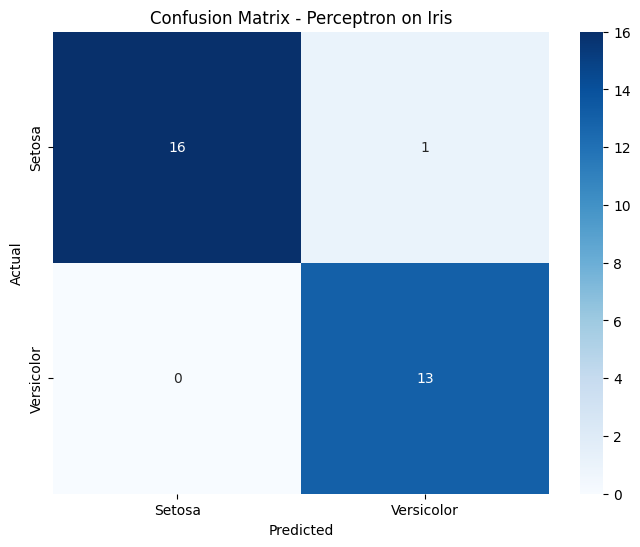

In [ ]:
from sklearn.datasets import load_iris
from sklearn.metrics import confusion_matrix, \
    classification_report
import seaborn as sns

# Load Iris dataset (2 classes only)
iris = load_iris()
X_iris = iris.data[:100, :2]  # First 2 classes, first 2 features
y_iris = iris.target[:100]
y_iris = np.where(y_iris == 0, -1, 1)  # Convert to -1/1

# Split and standardize
X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Perceptron with different learning rates
learning_rates = [0.001, 0.01, 0.1, 1.0]
best_acc = 0
best_lr = None
best_p = None

plt.figure(figsize=(15, 10))

for i, lr in enumerate(learning_rates):
    p = Perceptron(learning_rate=lr, n_epochs=100, random_state
                   =42)
    p.fit(X_train_scaled, y_train, verbose=False)

    train_acc = p.score(X_train_scaled, y_train)
    test_acc = p.score(X_test_scaled, y_test)

    plt.subplot(2, 2, i+1)
    plt.plot(p.errors_history, linewidth=2, marker='o',
             markersize=3)
    plt.xlabel('Epoch')
    plt.ylabel('Number of errors')
    plt.title(f'LR={lr} - Train: {train_acc:.2%}, Test: {test_acc\
:.2%}')
    plt.grid(True, alpha=0.3)

    if test_acc > best_acc:
        best_acc = test_acc
        best_lr = lr
        best_p = p

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("PERCEPTRON ON IRIS DATASET")
print("="*60)
print(f"Best learning rate: {best_lr}")
print(f"Best test accuracy: {best_acc:.2%}")
print(f"Final weights: {best_p.weights}")
print(f"Final bias: {best_p.bias:.4f}")

# Confusion matrix
test_pred = best_p.predict(X_test_scaled)
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Setosa', 'Versicolor'],
            yticklabels=['Setosa', 'Versicolor'])
plt.title('Confusion Matrix - Perceptron on Iris')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Decision boundary
plot_perceptron_decision_boundary(best_p, X_test_scaled, y_test,f"Perceptron on Iris (LR={ best_lr}, Acc={best_acc:.2%})")

# Perceptron with Non-Separable Data


PERCEPTRON ON NON-SEPARABLE DATA (CIRCLES)
Training accuracy: 53.33%
Test accuracy: 42.22%
Final errors: 102/210


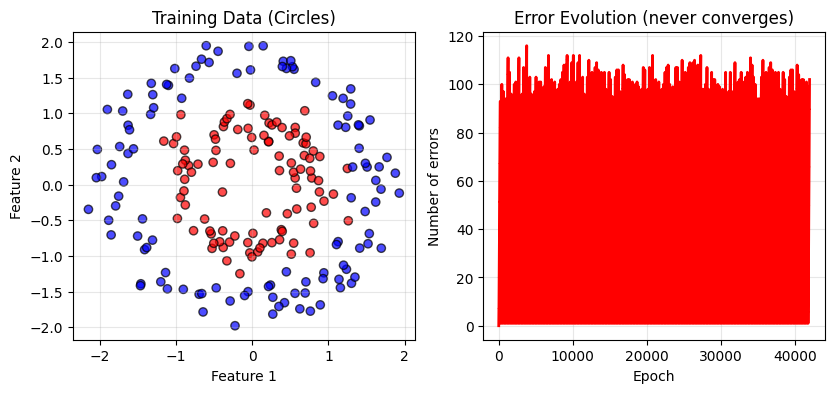

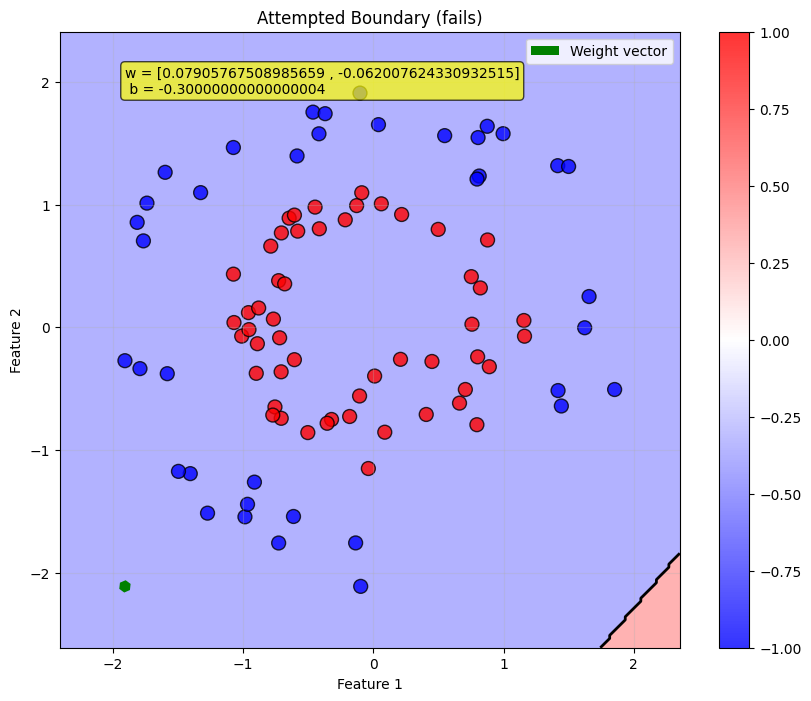

<Figure size 640x480 with 0 Axes>


CONCLUSION: The Perceptron cannot separate non-linearly separable data.
The error never reaches zero, and the decision boundary is inadequate.


In [13]:
# Generate non-linearly separable data (circles)
from sklearn.datasets import make_circles

X_circles, y_circles = make_circles(n_samples=300, factor=0.5,
    noise=0.1, random_state=42)
y_circles = np.where(y_circles == 0, -1, 1)

# Split
X_train, X_test, y_train, y_test = train_test_split(X_circles,
    y_circles, test_size=0.3, random_state=42)

# Standardize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Perceptron
p_circles = Perceptron(learning_rate=0.1, n_epochs=200,
    random_state=42)
p_circles.fit(X_train_scaled, y_train, verbose=False)

# Evaluate
train_acc = p_circles.score(X_train_scaled, y_train)
test_acc = p_circles.score(X_test_scaled, y_test)

print("\n" + "="*60)
print("PERCEPTRON ON NON-SEPARABLE DATA (CIRCLES)")
print("="*60)
print(f"Training accuracy: {train_acc:.2%}")
print(f"Test accuracy: {test_acc:.2%}")
print(f"Final errors: {p_circles.errors_history[-1]}/{len(y_train \
)}")

# Plot results
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y_train
    , cmap='bwr', edgecolors='black', alpha=0.7)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Training Data (Circles)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(p_circles.errors_history, linewidth=2, color='red')
plt.xlabel('Epoch')
plt.ylabel('Number of errors')
plt.title('Error Evolution (never converges)')
plt.grid(True, alpha=0.3)

# Plot decision boundary (even though it's not meaningful)
plot_perceptron_decision_boundary(p_circles, X_test_scaled,y_test, "Attempted Boundary (fails)")

plt.tight_layout()
plt.show()

print("\nCONCLUSION: The Perceptron cannot separate non-linearly \
separable data.")
print("The error never reaches zero, and the decision boundary is \
inadequate.")

# Comparison with Scikit-Learn Perceptron


COMPARISON WITH SCIKIT-LEARN PERCEPTRON
Our Perceptron - Test accuracy: 98.89%
sklearn Perceptron - Test accuracy: 96.67%

Our weights: [0.31596672 0.92090193]
sklearn weights: [-0.13320113  0.65394608]
Our bias: 0.0000
sklearn bias: 0.1000


<Figure size 1200x500 with 0 Axes>

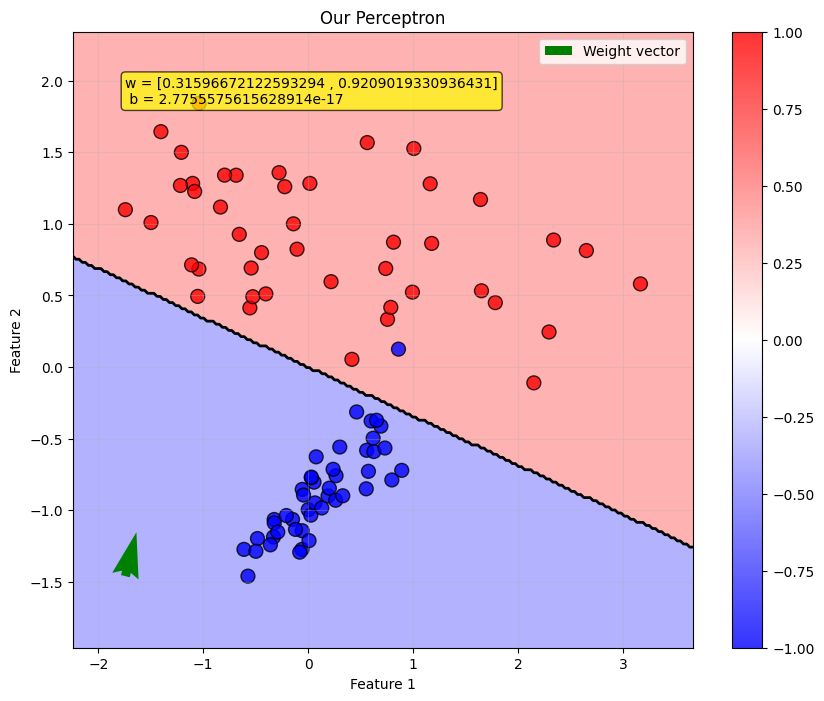

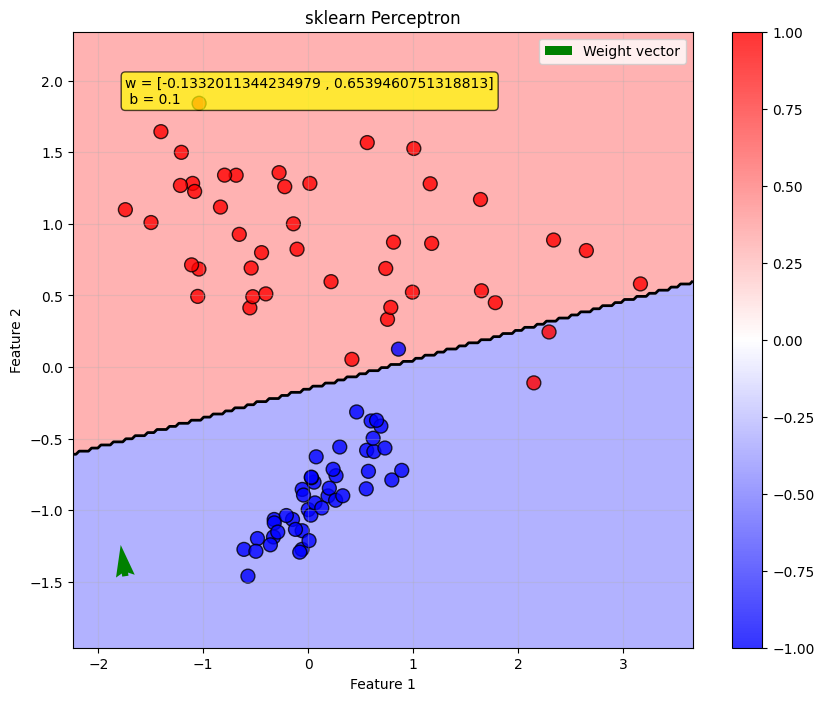

<Figure size 640x480 with 0 Axes>

In [14]:
from sklearn . linear_model import Perceptron as SklearnPerceptron
from sklearn . metrics import accuracy_score

# Generate data
X_sk, y_sk = make_classification(
    n_samples=300, n_features=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.5, random_state=42
)
y_sk = np.where(y_sk == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X_sk, y_sk,
    test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Our Perceptron
my_p = Perceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
my_p.fit(X_train_scaled, y_train, verbose=False)
my_pred = my_p.predict(X_test_scaled)
my_acc = accuracy_score(y_test, my_pred)

# sklearn Perceptron
sk_p = SklearnPerceptron(eta0=0.1, max_iter=50, random_state=42,
                         shuffle=True)
sk_p.fit(X_train_scaled, y_train)
sk_pred = sk_p.predict(X_test_scaled)
sk_acc = accuracy_score(y_test, sk_pred)

print("\n" + "="*60)
print("COMPARISON WITH SCIKIT-LEARN PERCEPTRON")
print("="*60)
print(f"Our Perceptron - Test accuracy: {my_acc:.2%}")
print(f"sklearn Perceptron - Test accuracy: {sk_acc:.2%}")
print(f"\nOur weights: {my_p.weights}")
print(f"sklearn weights: {sk_p.coef_[0]}")
print(f"Our bias: {my_p.bias:.4f}")
print(f"sklearn bias: {sk_p.intercept_[0]:.4f}")

# Visualize both decision boundaries
plt.figure(figsize=(12, 5))


plot_perceptron_decision_boundary(my_p, X_test_scaled, y_test,"Our Perceptron")


# For sklearn, we need to create a wrapper
class SklearnPerceptronWrapper:
    def __init__(self, model):
        self.model = model
        self.weights = model.coef_[0]
        self.bias = model.intercept_[0]

    def predict(self, X):
        return self.model.predict(X)

sk_wrapper = SklearnPerceptronWrapper(sk_p)
plot_perceptron_decision_boundary(sk_wrapper, X_test_scaled, y_test,"sklearn Perceptron")

plt.tight_layout()
plt.show()

# additional exercises


### averaged perceptron

In [15]:
class AveragedPerceptron:
    def __init__(self, learning_rate=0.01, n_iters=1000):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.bias = None
        self.avg_weights = None
        self.avg_bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        # Accumulators for the running sum
        self.avg_weights = np.zeros(n_features)
        self.avg_bias = 0
        
        # Total number of updates/steps to divide by at the end
        total_steps = 0

        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                # Standard Perceptron Update Logic
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = np.where(linear_output >= 0, 1, -1)

                if y[idx] != y_predicted:
                    update = self.lr * y[idx]
                    self.weights += update * x_i
                    self.bias += update

                # Accumulate current weights for the average
                self.avg_weights += self.weights
                self.avg_bias += self.bias
                total_steps += 1

        # Calculate final averaged parameters
        self.avg_weights /= total_steps
        self.avg_bias /= total_steps

    def predict(self, X):
        # Use the averaged parameters for inference
        linear_output = np.dot(X, self.avg_weights) + self.avg_bias
        return np.where(linear_output >= 0, 1, -1)


COMPARISON WITH SCIKIT-LEARN PERCEPTRON
Our Perceptron - Test accuracy: 98.89%
sklearn Perceptron - Test accuracy: 94.44%
Averaged Perceptron - Test accuracy: 95.56%

Our weights: [-0.05312939  0.22228686]
sklearn weights: [-0.13726876  0.18874179]
Averaged weights: [-0.05312939  0.22228686]
Our bias: 0.0000
sklearn bias: -0.1000
Averaged bias: 0.0000


<Figure size 1200x500 with 0 Axes>

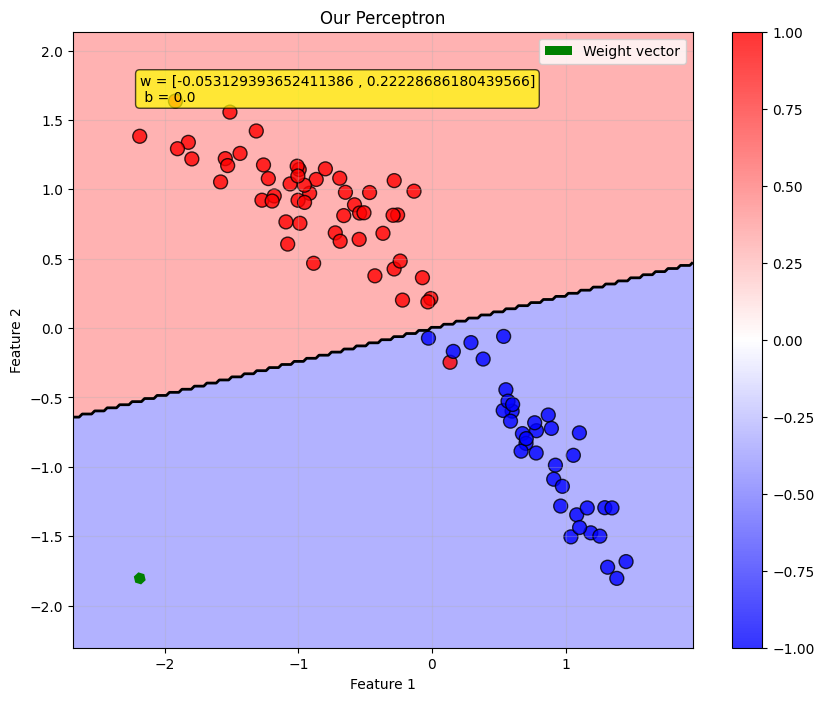

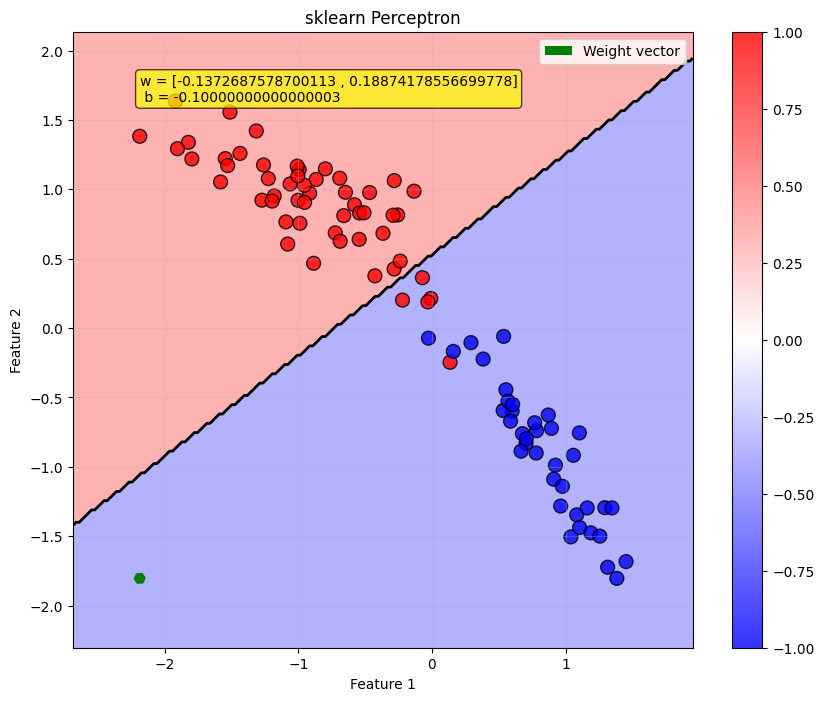

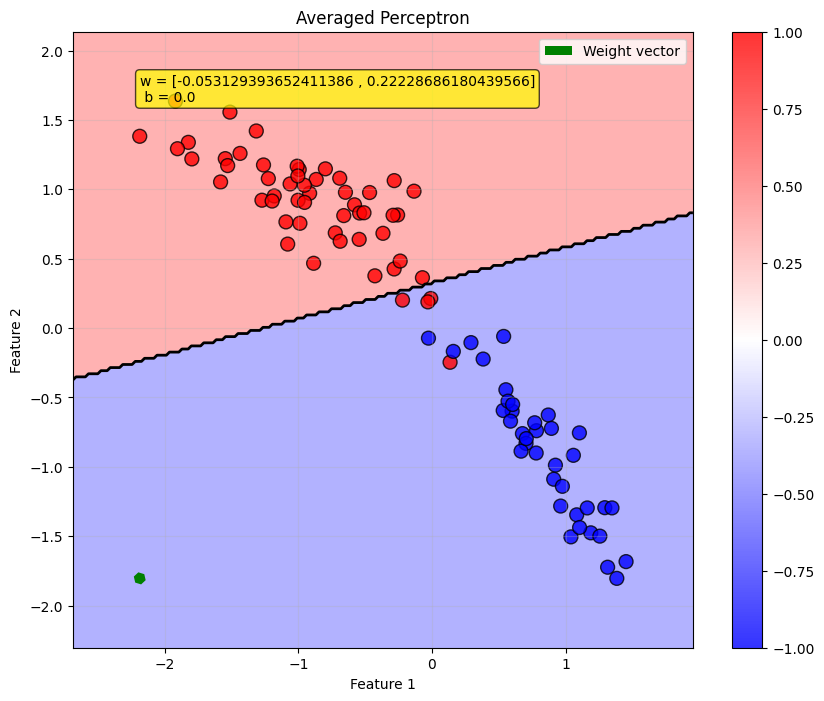

<Figure size 640x480 with 0 Axes>

In [ ]:

# Generate data
X_sk, y_sk = make_classification(
    n_samples=300, n_features=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.5, random_state=50
)
y_sk = np.where(y_sk == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X_sk, y_sk,
    test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Our Perceptron
my_p = Perceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
my_p.fit(X_train_scaled, y_train, verbose=False)
my_pred = my_p.predict(X_test_scaled)
my_acc = accuracy_score(y_test, my_pred)

# sklearn Perceptron
sk_p = SklearnPerceptron(eta0=0.1, max_iter=50, random_state=42,
                         shuffle=True)
sk_p.fit(X_train_scaled, y_train)
sk_pred = sk_p.predict(X_test_scaled)
sk_acc = accuracy_score(y_test, sk_pred)

# averaged perceptron
av_p = AveragedPerceptron(learning_rate=0.1, n_iters=50)
av_p.fit(X_train_scaled, y_train)
av_pred = av_p.predict(X_test_scaled)
av_acc = accuracy_score(y_test, av_pred)

print("\n" + "="*60)
print("COMPARISON WITH AVERAGED PERCEPTRON")
print("="*60)
print(f"Our Perceptron - Test accuracy: {my_acc:.2%}")
print(f"sklearn Perceptron - Test accuracy: {sk_acc:.2%}")
print(f"Averaged Perceptron - Test accuracy: {av_acc:.2%}")
print(f"\nOur weights: {my_p.weights}")
print(f"sklearn weights: {sk_p.coef_[0]}")
print(f"Averaged weights: {av_p.weights}")
print(f"Our bias: {my_p.bias:.4f}")
print(f"sklearn bias: {sk_p.intercept_[0]:.4f}")
print(f"Averaged bias: {av_p.bias:.4f}")

# Visualize both decision boundaries
plt.figure(figsize=(12, 5))


plot_perceptron_decision_boundary(my_p, X_test_scaled, y_test,"Our Perceptron")


# For sklearn, we need to create a wrapper
class SklearnPerceptronWrapper:
    def __init__(self, model):
        self.model = model
        self.weights = model.coef_[0]
        self.bias = model.intercept_[0]

    def predict(self, X):
        return self.model.predict(X)

sk_wrapper = SklearnPerceptronWrapper(sk_p)
plot_perceptron_decision_boundary(sk_wrapper, X_test_scaled, y_test,"sklearn Perceptron")
plot_perceptron_decision_boundary(av_p, X_test_scaled, y_test,"Averaged Perceptron")
plt.tight_layout()
plt.show()

### online vs batch

In [17]:
class BatchPerceptron(Perceptron):
    """ Perceptron classifier using Batch Learning """

    def fit(self, X, y, verbose=True):
        n_samples, n_features = X.shape

        if self.random_state:
            np.random.seed(self.random_state)

        self.weights = np.zeros(n_features)
        self.bias = 0
        self.errors_history = []
        self.weights_history = [self.weights.copy()]

        for epoch in range(self.n_epochs):
            # Accumulators for the batch update
            weight_update = np.zeros(n_features)
            bias_update = 0
            errors = 0

            for xi, target in zip(X, y):
                prediction = self.predict(xi.reshape(1, -1))[0]

                if prediction != target:
                    # Instead of updating self.weights immediately, 
                    # we accumulate the change
                    update = self.lr * target
                    weight_update += update * xi
                    bias_update += update
                    errors += 1

            # Apply the accumulated update once per epoch
            self.weights += weight_update
            self.bias += bias_update
            
            self.errors_history.append(errors)
            self.weights_history.append(self.weights.copy())

            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch + 1}/{self.n_epochs}, Errors: {errors}")

            if errors == 0:
                if verbose:
                    print(f"Converged at epoch {epoch + 1}")
                break

        return self

Epoch 10/50, Errors: 3
Epoch 20/50, Errors: 3
Epoch 30/50, Errors: 3
Epoch 40/50, Errors: 4
Epoch 50/50, Errors: 4

COMPARISON WITH SCIKIT-LEARN PERCEPTRON
Our Perceptron - Test accuracy: 98.89%
batch Perceptron - Test accuracy: 98.89%

Our weights: [0.31596672 0.92090193]
batch weights: [ 1.21402738 11.12343626]
Our bias: 0.0000
batch bias: 0.7000


<Figure size 1200x500 with 0 Axes>

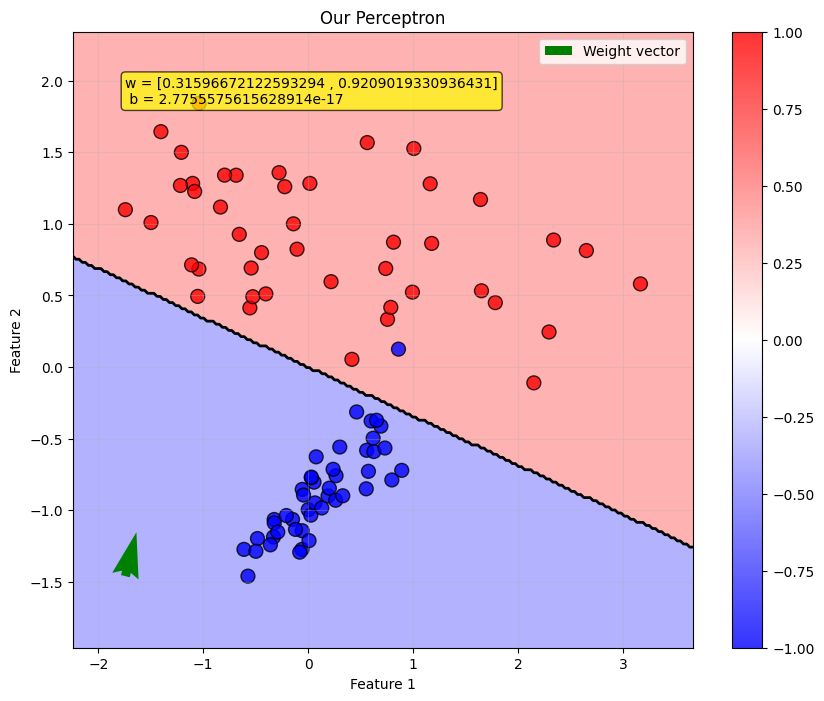

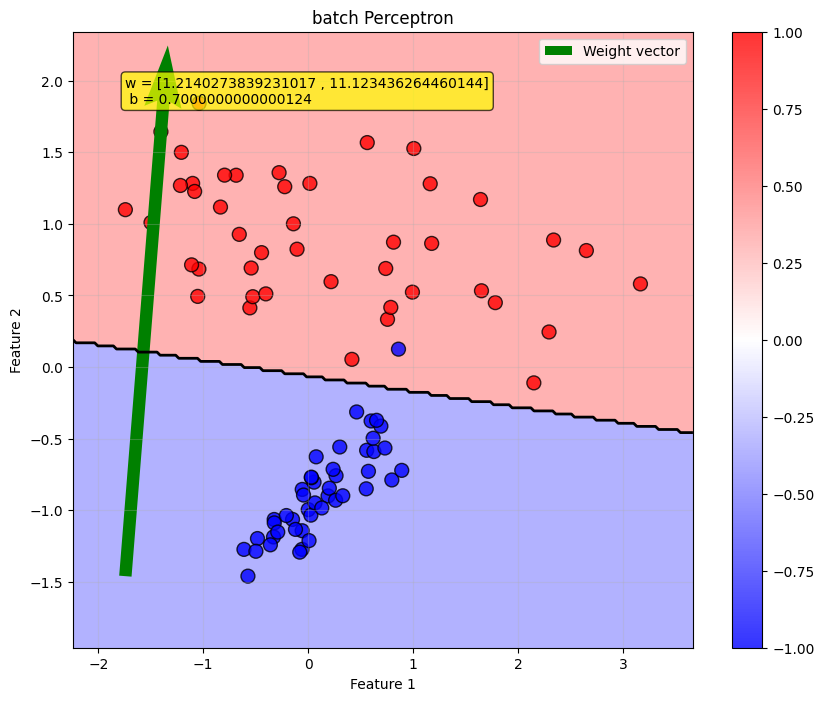

<Figure size 640x480 with 0 Axes>

In [ ]:
# Generate data
X_sk, y_sk = make_classification(
    n_samples=300, n_features=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.5, random_state=42
)
y_sk = np.where(y_sk == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X_sk, y_sk,
    test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Our Perceptron
my_p = Perceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
my_p.fit(X_train_scaled, y_train, verbose=False)
my_pred = my_p.predict(X_test_scaled)
my_acc = accuracy_score(y_test, my_pred)

# batch Perceptron
ba_p = BatchPerceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
ba_p.fit(X_train_scaled, y_train)
ba_pred = ba_p.predict(X_test_scaled)
ba_acc = accuracy_score(y_test, ba_pred)

print("\n" + "="*60)
print("COMPARISON WITH BATCH PERCEPTRON")
print("="*60)
print(f"Our Perceptron - Test accuracy: {my_acc:.2%}")
print(f"batch Perceptron - Test accuracy: {ba_acc:.2%}")
print(f"\nOur weights: {my_p.weights}")
print(f"batch weights: {ba_p.weights}")
print(f"Our bias: {my_p.bias:.4f}")
print(f"batch bias: {ba_p.bias:.4f}")

# Visualize both decision boundaries
plt.figure(figsize=(12, 5))


plot_perceptron_decision_boundary(my_p, X_test_scaled, y_test,"Our Perceptron")

plot_perceptron_decision_boundary(ba_p, X_test_scaled, y_test,"batch Perceptron")

plt.tight_layout()
plt.show()

### different weight init

In [41]:
def initialize_weights(strategy, n_features, random_state=None):
    if random_state:
        np.random.seed(random_state)
        
    if strategy == 'zeros':
        # Every weight starts at 0.0
        return np.zeros(n_features)
        
    elif strategy == 'small_random':
        # Values typically between -0.01 and 0.01
        return np.random.normal(loc=0.0, scale=0.01, size=n_features)
        
    elif strategy == 'large_random':
        # Values typically between -1.0 and 1.0 or larger
        return np.random.normal(loc=0.0, scale=10.0, size=n_features)
    

class weightPerceptron(Perceptron):
    """ Perceptron classifier using different weight init methods """

    def fit(self,strategy, X, y, verbose=True):
        n_samples, n_features = X.shape

        if self.random_state:
            np.random.seed(self.random_state)

        self.weights = initialize_weights(strategy,n_features=n_features)
        self.bias = 0
        self.errors_history = []
        self.weights_history = [self.weights.copy()]

        for epoch in range ( self.n_epochs ) :
            errors = 0

            for xi , target in zip (X , y ) :
            # Compute prediction
                prediction = self.predict ( xi.reshape (1 , -1) ) [0]

                # Update if prediction is wrong
                if prediction != target :
                    update = self.lr * target
                    self.weights += update * xi
                    self.bias += update
                    errors += 1

                self.errors_history.append ( errors )
                self.weights_history.append ( self.weights.copy () )

            if verbose and ( epoch + 1) % 10 == 0:
                print (f" Epoch { epoch +1}/{ self.n_epochs } , Errors :    { errors } " )

            # Early stopping if no errors
            if errors == 0:
                if verbose :
                    print (f" Converged at epoch { epoch + 1} " )
                break

        return self

 Epoch 10/50 , Errors :    8 
 Epoch 20/50 , Errors :    6 
 Epoch 30/50 , Errors :    7 
 Epoch 40/50 , Errors :    5 
 Epoch 50/50 , Errors :    6 
 Epoch 10/50 , Errors :    5 
 Epoch 20/50 , Errors :    4 
 Epoch 30/50 , Errors :    4 
 Epoch 40/50 , Errors :    6 
 Epoch 50/50 , Errors :    5 

COMPARISON WITH BATCH PERCEPTRON
Our Perceptron - Test accuracy: 98.89%
small random Perceptron - Test accuracy: 98.89%
large random Perceptron - Test accuracy: 98.89%

Our weights: [0.31596672 0.92090193]
small random weights: [0.31380576 0.87127931]
large random weights: [0.31319228 0.88886461]
Our bias: 0.0000
small random bias: 0.0000
large random bias: 0.0000


<Figure size 1200x500 with 0 Axes>

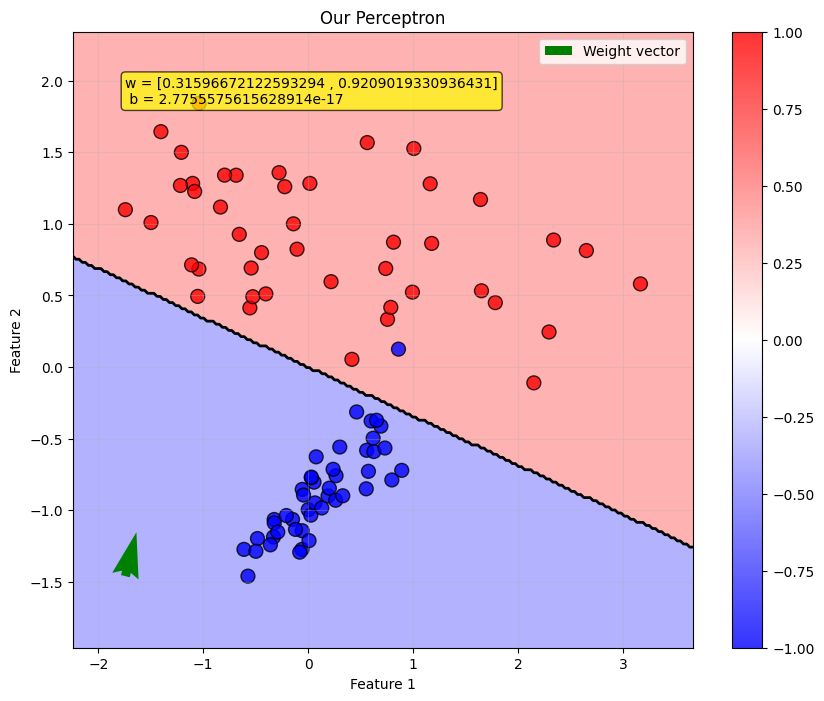

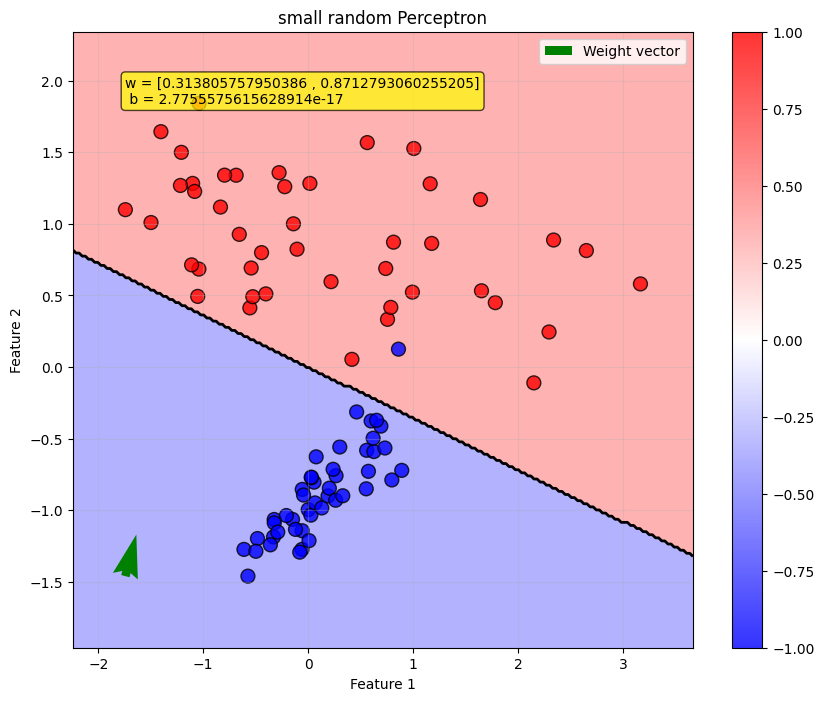

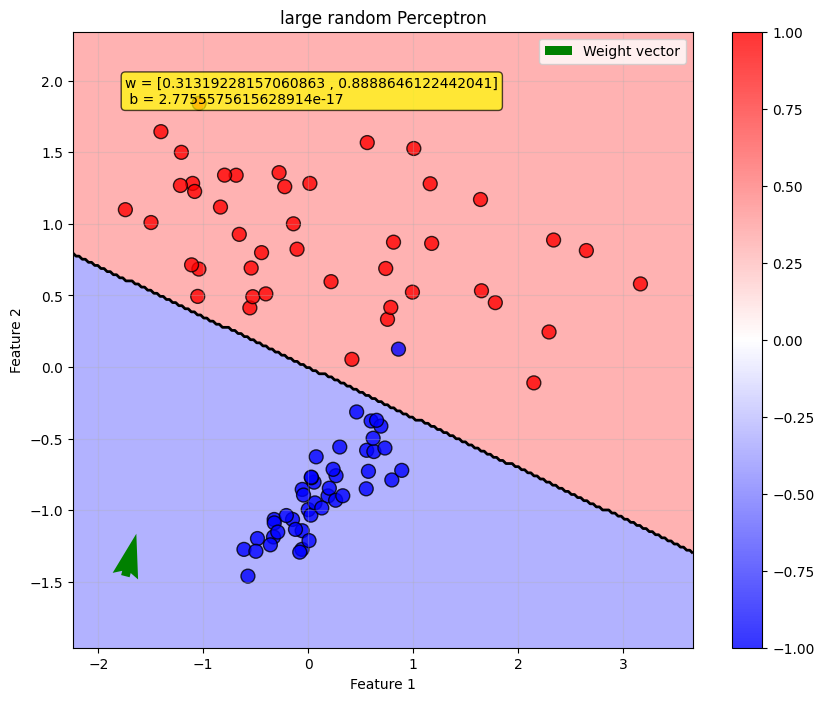

<Figure size 640x480 with 0 Axes>

In [42]:
# Generate data
X_sk, y_sk = make_classification(
    n_samples=300, n_features=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.5, random_state=42
)
y_sk = np.where(y_sk == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X_sk, y_sk,
    test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Our Perceptron
my_p = Perceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
my_p.fit(X_train_scaled, y_train, verbose=False)
my_pred = my_p.predict(X_test_scaled)
my_acc = accuracy_score(y_test, my_pred)

# small random Perceptron
sr_p = weightPerceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
sr_p.fit(strategy="small_random",X=X_train_scaled, y=y_train)
sr_pred = sr_p.predict(X_test_scaled)
sr_acc = accuracy_score(y_test, sr_pred)

# large random Perceptron
lr_p = weightPerceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
lr_p.fit(strategy="large_random",X=X_train_scaled, y=y_train)
lr_pred = lr_p.predict(X_test_scaled)
lr_acc = accuracy_score(y_test, lr_pred)

print("\n" + "="*60)
print("COMPARISON WITH BATCH PERCEPTRON")
print("="*60)
print(f"Our Perceptron - Test accuracy: {my_acc:.2%}")
print(f"small random Perceptron - Test accuracy: {sr_acc:.2%}")
print(f"large random Perceptron - Test accuracy: {lr_acc:.2%}")
print(f"\nOur weights: {my_p.weights}")
print(f"small random weights: {sr_p.weights}")
print(f"large random weights: {lr_p.weights}")
print(f"Our bias: {my_p.bias:.4f}")
print(f"small random bias: {sr_p.bias:.4f}")
print(f"large random bias: {lr_p.bias:.4f}")

# Visualize both decision boundaries
plt.figure(figsize=(12, 5))


plot_perceptron_decision_boundary(my_p, X_test_scaled, y_test,"Our Perceptron")
plot_perceptron_decision_boundary(sr_p, X_test_scaled, y_test,"small random Perceptron")
plot_perceptron_decision_boundary(lr_p, X_test_scaled, y_test,"large random Perceptron")

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Number of errors')

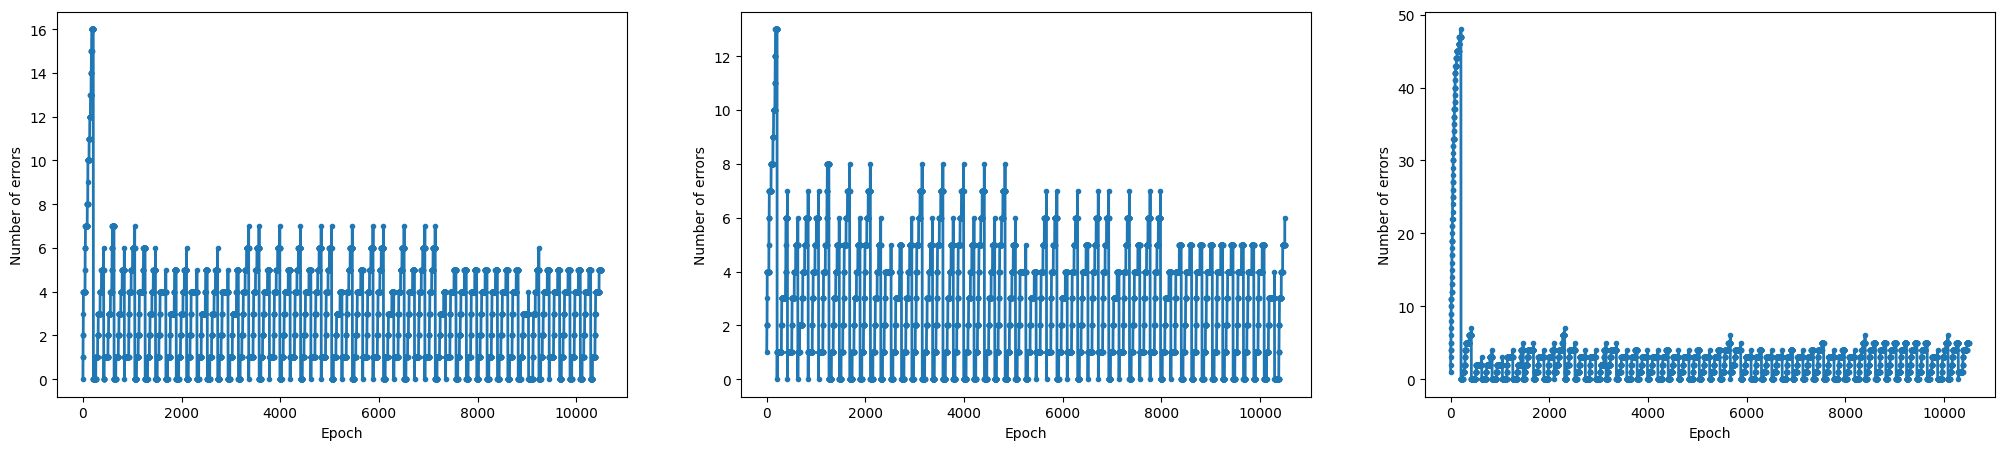

In [43]:
plt.figure(figsize=(25, 5))
plt.subplot(1,3,1)
plt.plot(my_p.errors_history, linewidth=2, marker='o',
             markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Number of errors')
plt.subplot(1,3,2)
plt.plot(sr_p.errors_history, linewidth=2, marker='o',
             markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Number of errors')
plt.subplot(1,3,3)
plt.plot(lr_p.errors_history, linewidth=2, marker='o',
             markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Number of errors')

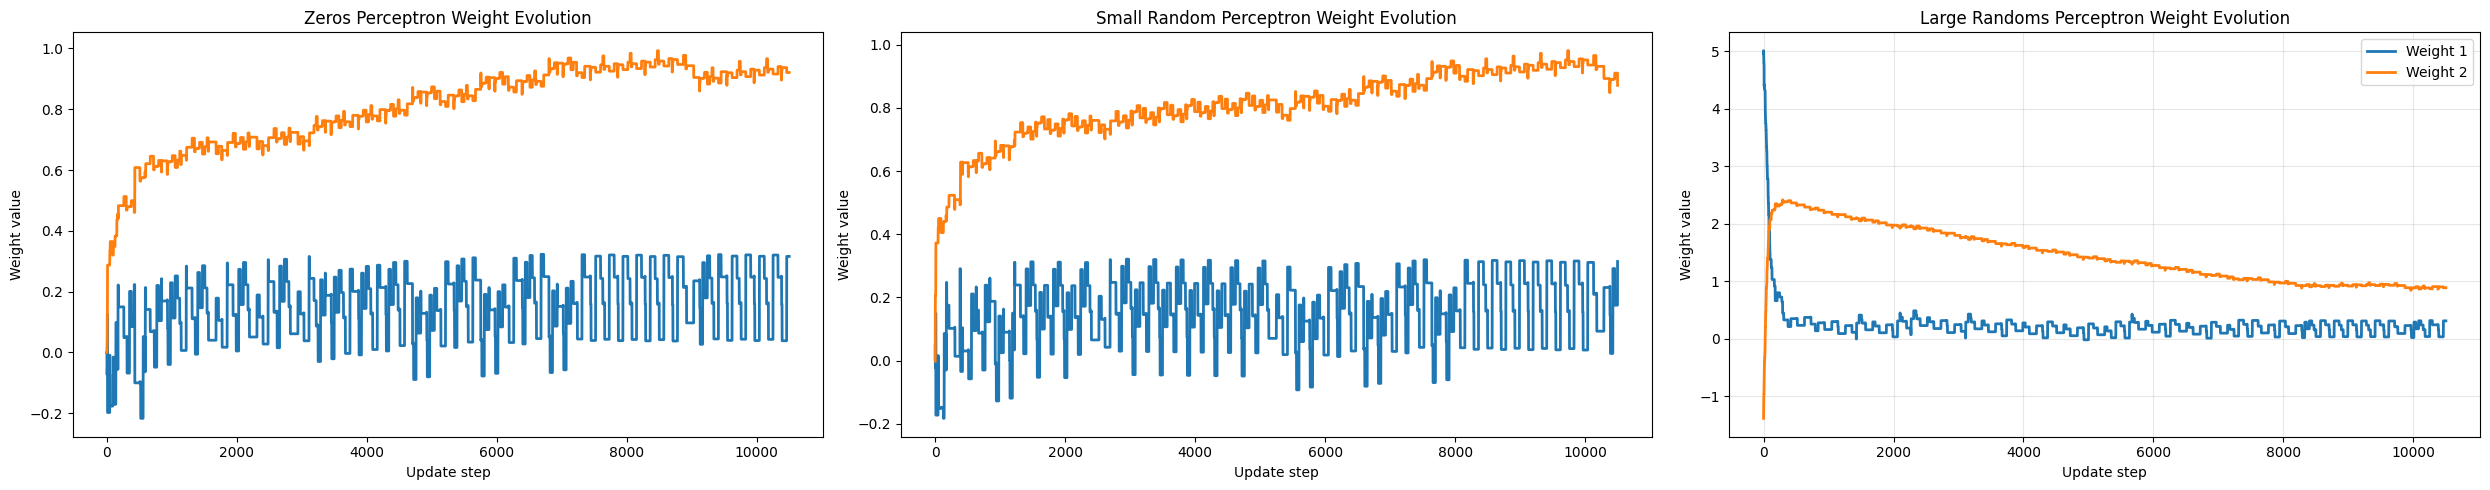

In [44]:
plt.figure(figsize=(25, 5))
plt.subplot (1 , 3 ,1 )
weights_history = np.array ( my_p.weights_history )
plt.plot ( weights_history [: , 0] , label ='Weight 1', linewidth
=2)
plt.plot ( weights_history [: , 1] , label ='Weight 2', linewidth
=2)
plt.xlabel ('Update step')
plt.ylabel ('Weight value')
plt.title ('Zeros Perceptron Weight Evolution')
plt.subplot (1 , 3 ,2)
weights_history = np.array ( sr_p.weights_history )
plt.plot ( weights_history [: , 0] , label ='Weight 1', linewidth
=2)
plt.plot ( weights_history [: , 1] , label ='Weight 2', linewidth
=2)
plt.xlabel ('Update step')
plt.ylabel ('Weight value')
plt.title ('Small Random Perceptron Weight Evolution')
plt.subplot (1 , 3 ,3 )
weights_history = np.array ( lr_p.weights_history )
plt.plot ( weights_history [: , 0] , label ='Weight 1', linewidth
=2)
plt.plot ( weights_history [: , 1] , label ='Weight 2', linewidth
=2)
plt.xlabel ('Update step')
plt.ylabel ('Weight value')
plt.title ('Large Randoms Perceptron Weight Evolution')
plt.legend ()
plt.grid ( True , alpha =0.3)
plt.tight_layout ()
plt.show ()

### margin perceptron

In [49]:
class MarginPerceptron(Perceptron):
    def __init__(self, learning_rate=0.01, n_epochs=50, margin=1.0, random_state=None):
        super().__init__(learning_rate, n_epochs, random_state)
        self.margin = margin

    def fit(self, X, y, verbose=True):
        n_samples, n_features = X.shape
        if self.random_state:
            np.random.seed(self.random_state)

        self.weights = np.zeros(n_features)
        self.bias = 0
        self.errors_history = []
        self.weights_history = [ self.weights.copy () ]

        

        for epoch in range(self.n_epochs):
            updates_in_epoch = 0
            
            for xi, target in zip(X, y):
                # Calculate the functional margin: target * (w.x + b)
                # If this value is positive, it's correctly classified.
                # If it's > self.margin, it's correctly classified AND outside the safety zone.
                score = target * (np.dot(xi, self.weights) + self.bias)

                if score < self.margin:
                    update = self.lr * target
                    self.weights += update * xi
                    self.bias += update
                    updates_in_epoch += 1
            
            self.errors_history.append(updates_in_epoch)
            self.weights_history.append ( self.weights.copy () )

            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}: {updates_in_epoch} updates performed")

            if updates_in_epoch == 0:
                break
        return self

Epoch 10: 14 updates performed
Epoch 20: 11 updates performed
Epoch 30: 9 updates performed
Epoch 40: 9 updates performed
Epoch 50: 9 updates performed

COMPARISON WITH BATCH PERCEPTRON
Our Perceptron - Test accuracy: 98.89%
margin Perceptron - Test accuracy: 98.89%

Our weights: [0.31596672 0.92090193]
margin perceptron weights: [0.94031902 5.88358801]
Our bias: 0.0000
margin perceptron bias: 0.2000


Text(0.5, 1.0, 'Margin Perceptron Weight Evolution')

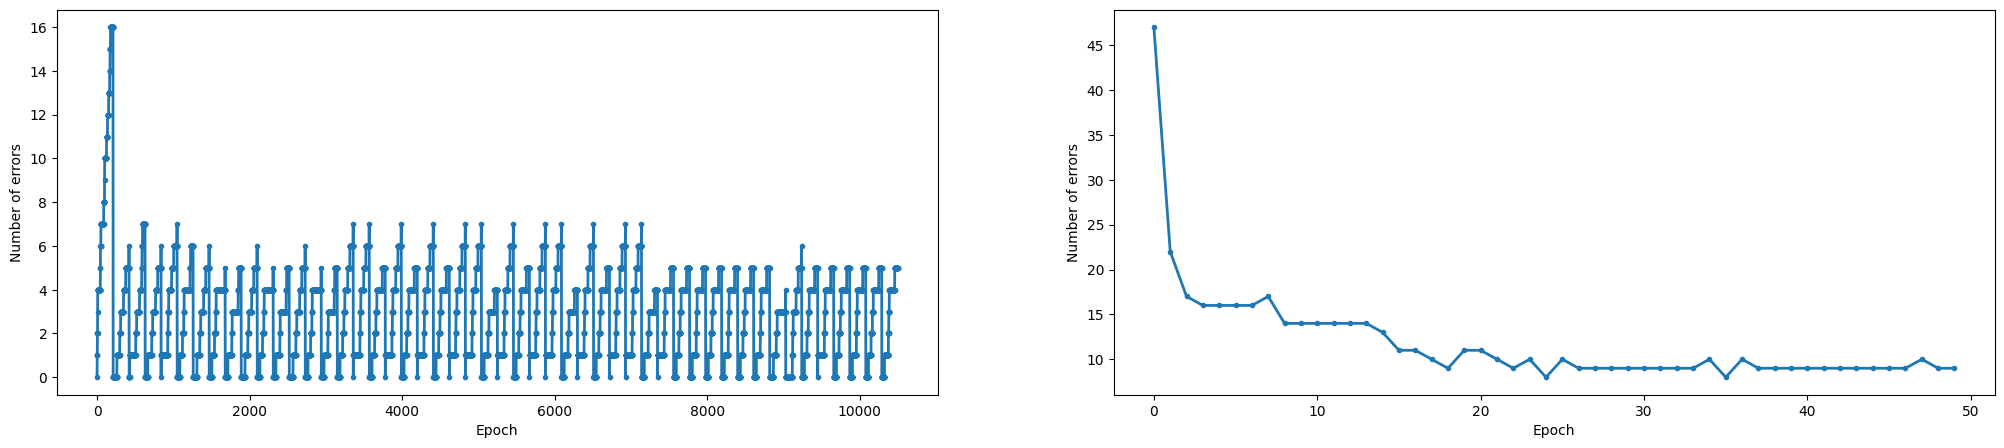

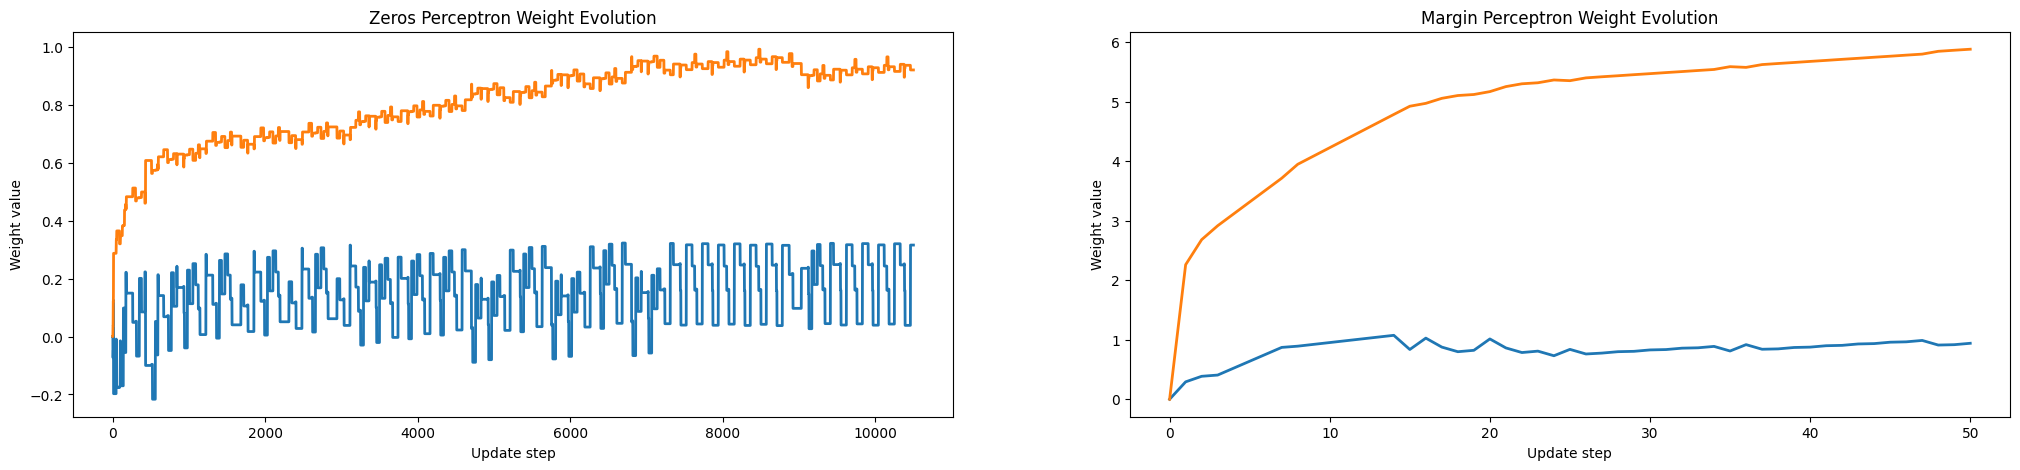

In [50]:
# Generate data
X_sk, y_sk = make_classification(
    n_samples=300, n_features=2, n_redundant=0,
    n_clusters_per_class=1, class_sep=1.5, random_state=42
)
y_sk = np.where(y_sk == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X_sk, y_sk,
    test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Our Perceptron
my_p = Perceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
my_p.fit(X_train_scaled, y_train, verbose=False)
my_pred = my_p.predict(X_test_scaled)
my_acc = accuracy_score(y_test, my_pred)

# margin Perceptron
sr_p = MarginPerceptron(learning_rate=0.1, n_epochs=50, random_state
                  =42)
sr_p.fit(X=X_train_scaled, y=y_train)
sr_pred = sr_p.predict(X_test_scaled)
sr_acc = accuracy_score(y_test, sr_pred)



print("\n" + "="*60)
print("COMPARISON WITH BATCH PERCEPTRON")
print("="*60)
print(f"Our Perceptron - Test accuracy: {my_acc:.2%}")
print(f"margin Perceptron - Test accuracy: {sr_acc:.2%}")

print(f"\nOur weights: {my_p.weights}")
print(f"margin perceptron weights: {sr_p.weights}")

print(f"Our bias: {my_p.bias:.4f}")
print(f"margin perceptron bias: {sr_p.bias:.4f}")

plt.figure(figsize=(25, 5))
plt.subplot(1,2,1)
plt.plot(my_p.errors_history, linewidth=2, marker='o',
             markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Number of errors')
plt.subplot(1,2,2)
plt.plot(sr_p.errors_history, linewidth=2, marker='o',
             markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Number of errors')


plt.figure(figsize=(25, 5))
plt.subplot (1 , 2 ,1 )
weights_history = np.array ( my_p.weights_history )
plt.plot ( weights_history [: , 0] , label ='Weight 1', linewidth
=2)
plt.plot ( weights_history [: , 1] , label ='Weight 2', linewidth
=2)
plt.xlabel ('Update step')
plt.ylabel ('Weight value')
plt.title ('Zeros Perceptron Weight Evolution')
plt.subplot (1 , 2 ,2)
weights_history = np.array ( sr_p.weights_history )
plt.plot ( weights_history [: , 0] , label ='Weight 1', linewidth
=2)
plt.plot ( weights_history [: , 1] , label ='Weight 2', linewidth
=2)
plt.xlabel ('Update step')
plt.ylabel ('Weight value')
plt.title ('Margin Perceptron Weight Evolution')